<a href="https://colab.research.google.com/github/emmanresu/Thesis-Keras/blob/latest%2Funstable/rice_stocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Import libraries



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime

np.set_printoptions(legacy='1.25')

## Data - testing

In [ ]:
rice_stocks = 'rice_test.csv'
rice = pd.read_csv(rice_stocks)

rice

FileNotFoundError: [Errno 2] No such file or directory: 'rice_test.csv'

In [ ]:
for i in range(len(rice.columns)):
  if rice.columns[i]
  datetime.strptime(rice.columns[i], '%B')

In [ ]:
months = set(rice.columns[2::])
months

In [ ]:

datetime.strptime(rice.columns[2], '%B')
i = 0
rice.columns[i]
isinstance(rice.columns[0], str)

In [ ]:
for i in range(len(rice.index)):
  for j in range(len(rice.columns)):
    if rice.columns[j] in months:
      month = datetime.strptime((rice.columns[j], '%B'), datetime).strftime('%m')
      print(month, rice.iloc[i, j])
    else:
      print(rice.iloc[i, j])


## Functions for processing data

In [2]:
# match columns of rice stocks and rice prices

def combine(inv, prc):
  curr_price = 0
  pointer = 0

  data = []

  for i in range(len(inv)):
    if pointer == len(prc):
      pointer = len(prc) - 1

    curr_price = prc.iloc[pointer]['price']
    prev = prc.iloc[pointer - 1]['price']

    if inv.iloc[i]['date'] == prc.iloc[pointer]['date']:
      data.append(curr_price)
      pointer += 1
    elif inv.iloc[i]['date'] < prc.iloc[pointer - 1]['date']:
      data.append(prev)
    else:
      data.append(curr_price)

  return data

In [3]:
def add_month(data):
  new_data = []
  mon_len = 0
  month = 1

  while(len(data) > mon_len):
      input = datetime.strptime(str(month), "%m")
      input = input.strftime("%m")
      new_data.append(input)
      mon_len += 1
      month += 1

      if month == 13:
          month = 1

  return new_data

In [4]:
# transforms the tabular data into a time series

def timeseries(data, drop_col):

  new_data = []

  for i in data.index:
    for j in data.columns:

      if j != None:
        year_month_str = f"{i}-{j}"
        year_month_obj = datetime.strptime(year_month_str, '%Y-%B')
        year_month = year_month_obj.strftime('%Y-%m')

        month_obj = datetime.strptime(j, '%B')
        month = month_obj.strftime('%m')

        new_data.append([year_month, month, float(data.at[i, j])])
      else:
        break

  if drop_col != None:
    new_data = np.delete(new_data, drop_col, axis=1)

  return new_data

In [5]:
'''
Add categorical values 'is_lean_month'
0 if not a lean month, 1 if in lean month
Lean months are July (07), August (08), and September (09)
'''

# def add_lean_months(dataset):
#   lean = set([7, 8, 9])
#   dataset['is_lean_month'] = np.where(pd.to_datetime(dataset['date']).dt.month.isin(lean), '1', '0')
#   return dataset

def add_lean_months(dataset):
  lean = set([7, 8, 9])
  dataset['is_lean_month'] = np.where(dataset.index.month.isin(lean), 1, 0)
  return dataset

In [6]:
testing = ["Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month", "Month"]

n_data = add_month(testing)
print(n_data)

['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '01', '02']


## New dataset

In [ ]:
total_stock = 'total_stock.csv'
stock_household = 'household_stock.csv'
stock_commercial = 'commercial_stock.csv'
stock_nfa = 'nfa_stock.csv'


total = pd.read_csv(total_stock, index_col=[0])
household = pd.read_csv(stock_household, index_col=[0])
commercial = pd.read_csv(stock_commercial, index_col=[0])
nfa = pd.read_csv(stock_nfa, index_col=[0])

In [ ]:
dataset = timeseries(total, None)
hh_dataset = timeseries(household, [0, 1])
comm_dataset = timeseries(commercial, [0, 1])
nfa_dataset = timeseries(nfa, [0, 1])


dataset_df = pd.DataFrame(dataset, columns=['date', 'month', 'stock_total'])
hh_dataset_df = pd.DataFrame(hh_dataset, columns=['stock_household'])
comm_dataset_df = pd.DataFrame(comm_dataset, columns=['stock_commercial'])
nfa_dataset_df = pd.DataFrame(nfa_dataset, columns=['stock_nfa'])

dataset_df = dataset_df.join(hh_dataset_df).join(comm_dataset_df).join(nfa_dataset_df)

dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0
...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0


### Wholesale Prices

In [ ]:
prices = 'prices_ws_2000-2024.csv'
prices_wholesale = pd.read_csv(prices, index_col=[0])

prices_wholesale = prices_wholesale.iloc[1:]

prices_wholesale = prices_wholesale.reset_index()
prices_wholesale.columns = prices_wholesale.iloc[0]
prices_wholesale = prices_wholesale.drop(index=0)

prices_wholesale.reset_index(inplace=True, drop=True)
prices_wholesale = prices_wholesale.drop(index=[300, 301])

In [ ]:
prices_2025 = 'prices_ws_2025.csv'
prices_ws_2025 = pd.read_csv(prices_2025, index_col=[0])

prices_ws_2025 = prices_ws_2025.iloc[1:]

prices_ws_2025 = prices_ws_2025.reset_index()
prices_ws_2025.columns = prices_ws_2025.iloc[0]
prices_ws_2025 = prices_ws_2025.drop(index=0)

prices_ws_2025.reset_index(inplace=True, drop=True)

In [ ]:
added_month = add_month(prices_wholesale)

prices_wholesale['month'] = added_month
prices_wholesale['date'] = prices_wholesale['Year'] + "-" + prices_wholesale['month']

In [ ]:
prices_wholesale = prices_wholesale[['date', 'Regular', 'Milled']]
prices_wholesale = prices_wholesale.rename(columns={'Regular' : 'price_regular', 'Milled' : 'price_milled'})
prices_wholesale

,date,price_regular,price_milled
0,2000-01,15.65,17.38
1,2000-02,15.83,17.57
2,2000-03,15.98,17.64
3,2000-04,16.05,17.62
4,2000-05,16.29,17.75
...,...,...,...
295,2024-08,46.34,49.84
296,2024-09,45.62,49.25
297,2024-10,44.79,48.47
298,2024-11,43.89,47.75


In [ ]:
added_month_2025 = add_month(prices_ws_2025)

prices_ws_2025['month'] = added_month_2025
prices_ws_2025['date'] = prices_ws_2025['Year'] + "-" + prices_ws_2025['month']

In [ ]:
prices_ws_2025 = prices_ws_2025[['date', 'Regular', 'Milled']]
prices_ws_2025 = prices_ws_2025.rename(columns={'Regular' : 'price_regular',
                                                'Milled' : 'price_milled'})
prices_ws_2025

,date,price_regular,price_milled
0,2025-01,42.66,46.91
1,2025-02,41.32,45.79
2,2025-03,39.86,44.46
3,2025-04,38.33,42.94
4,2025-05,37.13,41.62
5,2025-06,36.5,40.97
6,2025-07,35.44,40.05
7,2025-08,35.23,39.69
8,2025-09,35.14,39.61
9,2025-10,34.68,39.48


In [ ]:
prices_wholesale = pd.concat([prices_wholesale, prices_ws_2025], ignore_index=True)
prices_wholesale = prices_wholesale.rename(columns={'price_regular' : 'regular_wholesale_price',
                                                'price_milled' : 'milled_wholesale_price'})
prices_wholesale

,date,regular_wholesale_price,milled_wholesale_price
0,2000-01,15.65,17.38
1,2000-02,15.83,17.57
2,2000-03,15.98,17.64
3,2000-04,16.05,17.62
4,2000-05,16.29,17.75
...,...,...,...
307,2025-08,35.23,39.69
308,2025-09,35.14,39.61
309,2025-10,34.68,39.48
310,2025-11,35.65,40.28


In [ ]:
dataset_df = pd.merge(dataset_df, prices_wholesale, on='date', how='inner')
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75
...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28


### Retail prices

In [ ]:
prices_r = 'prices_r_2000-2024.csv'
prices_retail = pd.read_csv(prices_r, index_col=[0])

prices_retail = prices_retail.iloc[1:]

prices_retail = prices_retail.reset_index()
prices_retail.columns = prices_retail.iloc[0]
prices_retail = prices_retail.drop(index=0)

prices_retail.reset_index(inplace=True, drop=True)
prices_retail = prices_retail.drop(index=[300, 301])

In [ ]:
prices_r_2025 = 'prices_r_2025.csv'
prices_r_2025 = pd.read_csv(prices_r_2025, index_col=[0])

prices_r_2025 = prices_r_2025.iloc[1:]

prices_r_2025 = prices_r_2025.reset_index()
prices_r_2025.columns = prices_r_2025.iloc[0]
prices_r_2025 = prices_r_2025.drop(index=0)

prices_r_2025.reset_index(inplace=True, drop=True)

In [ ]:
added_month_retail = add_month(prices_retail)

prices_retail['month'] = added_month_retail
prices_retail['date'] = prices_retail['Year'] + "-" + prices_retail['month']

In [ ]:
prices_retail = prices_retail[['date', 'Regular', 'Milled']]
prices_retail = prices_retail.rename(columns={'Regular' : 'price_regular', 'Milled' : 'price_milled'})
prices_retail

,date,price_regular,price_milled
0,2000-01,17.05,19
1,2000-02,17.2,19.12
2,2000-03,17.32,19.22
3,2000-04,17.38,19.21
4,2000-05,17.45,19.27
...,...,...,...
295,2024-08,50.66,55.56
296,2024-09,50.47,55.51
297,2024-10,50.22,55.28
298,2024-11,49.24,54.64


In [ ]:
added_month_retail_2025 = add_month(prices_r_2025)

prices_r_2025['month'] = added_month_retail_2025
prices_r_2025['date'] = prices_r_2025['Year'] + "-" + prices_r_2025['month']

In [ ]:
prices_r_2025 = prices_r_2025[['date', 'Regular', 'Milled']]
prices_r_2025 = prices_r_2025.rename(columns={'Regular' : 'price_regular',
                                                'Milled' : 'price_milled'})
prices_r_2025

,date,price_regular,price_milled
0,2025-01,48.25,54.14
1,2025-02,47.23,53.46
2,2025-03,46.09,52.25
3,2025-04,44.45,50.54
4,2025-05,43.19,49.45
5,2025-06,42.35,48.47
6,2025-07,41.31,47.6
7,2025-08,40.43,46.51
8,2025-09,40.23,46.5
9,2025-10,40.09,46.49


In [ ]:
prices_retail = pd.concat([prices_retail, prices_r_2025], ignore_index=True)
prices_retail = prices_retail.rename(columns={'price_regular' : 'regular_retail_price',
                                                'price_milled' : 'milled_retail_price'})
prices_retail

,date,regular_retail_price,milled_retail_price
0,2000-01,17.05,19
1,2000-02,17.2,19.12
2,2000-03,17.32,19.22
3,2000-04,17.38,19.21
4,2000-05,17.45,19.27
...,...,...,...
307,2025-08,40.43,46.51
308,2025-09,40.23,46.5
309,2025-10,40.09,46.49
310,2025-11,40.29,46.8


In [ ]:
dataset_df = pd.merge(dataset_df, prices_retail, on='date', how='inner')
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38,17.05,19
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57,17.2,19.12
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64,17.32,19.22
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62,17.38,19.21
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75,17.45,19.27
...,...,...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,40.43,46.51
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,40.23,46.5
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,40.09,46.49
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,40.29,46.8


### Lean months

In [ ]:
# Input binary data: 1 if lean month, 0 if not

dataset_df = add_lean_months(dataset_df)
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38,17.05,19,0
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57,17.2,19.12,0
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64,17.32,19.22,0
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62,17.38,19.21,0
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,40.43,46.51,1
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,40.23,46.5,1
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,40.09,46.49,0
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,40.29,46.8,0


In [ ]:
dataset_df

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
0,2000-01,01,2364500.00,1149700.0,488200.0,726600.0,15.65,17.38,17.05,19,0
1,2000-02,02,2042300.00,1009500.0,420600.0,612200.0,15.83,17.57,17.2,19.12,0
2,2000-03,03,1765700.00,832200.0,381000.0,552500.0,15.98,17.64,17.32,19.22,0
3,2000-04,04,1874900.00,954400.0,441200.0,479300.0,16.05,17.62,17.38,19.21,0
4,2000-05,05,2067000.00,1059500.0,509600.0,497900.0,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...,...
307,2025-08,08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,40.43,46.51,1
308,2025-09,09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,40.23,46.5,1
309,2025-10,10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,40.09,46.49,0
310,2025-11,11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,40.29,46.8,0


### Save dataset

In [ ]:
dataset_df.to_csv('dataset.csv')

## Additional entries

In [ ]:
total_stock = 'total_stock_2026.csv'
stock_household = 'household_stock_2026.csv'
stock_commercial = 'commercial_stock_2026.csv'
stock_nfa = 'nfa_stock_2026.csv'

total = pd.read_csv(total_stock, index_col=[0])
household = pd.read_csv(stock_household, index_col=[0])
commercial = pd.read_csv(stock_commercial, index_col=[0])
nfa = pd.read_csv(stock_nfa, index_col=[0])

In [ ]:
data_additional = timeseries(total, None)
hh_dataset = timeseries(household, [0, 1])
comm_dataset = timeseries(commercial, [0, 1])
nfa_dataset = timeseries(nfa, [0, 1])

data_additional = pd.DataFrame(data_additional, columns=['date', 'month', 'stock_total'])
hh_dataset_df = pd.DataFrame(hh_dataset, columns=['stock_household'])
comm_dataset_df = pd.DataFrame(comm_dataset, columns=['stock_commercial'])
nfa_dataset_df = pd.DataFrame(nfa_dataset, columns=['stock_nfa'])

data_additional = data_additional.join(hh_dataset_df).join(comm_dataset_df).join(nfa_dataset_df)

data_additional

,date,month,stock_total,stock_household,stock_commercial,stock_nfa
0,2026-01,01,2341155.06,1043525.46,858877.0,438752.6
1,2026-02,02,2112282.15,899568.63,791200.85,421512.67
2,2026-03,03,1877328.88,908721.92,564220.75,404386.21


In [ ]:
rice_prices_2026 = 'rice_prices_2026.csv'
prices = pd.read_csv(rice_prices_2026, index_col=[0])
prices = prices.reset_index()
prices = pd.DataFrame(prices, columns=['date', 'regular_wholesale_price', 'milled_wholesale_price',
                                       'regular_retail_price', 'milled_retail_price'])
prices

,date,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
0,2026-01,39.81,45.16,43.29,50.05
1,2026-02,41.60,47.72,45.27,52.21
2,2026-03,44.71,50.06,47.72,54.88


In [ ]:
data_additional = pd.merge(data_additional, prices, on='date', how='inner')
data_additional

,date,month,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
0,2026-01,01,2341155.06,1043525.46,858877.0,438752.6,39.81,45.16,43.29,50.05
1,2026-02,02,2112282.15,899568.63,791200.85,421512.67,41.60,47.72,45.27,52.21
2,2026-03,03,1877328.88,908721.92,564220.75,404386.21,44.71,50.06,47.72,54.88


In [ ]:
dataset_df = pd.concat([dataset_df, data_additional], ignore_index=True)
add_lean_months(dataset_df)
print(dataset_df.to_string())

        date month  stock_total stock_household stock_commercial  stock_nfa  regular_wholesale_price  milled_wholesale_price  regular_retail_price  milled_retail_price is_lean_month
0    2000-01     1   2364500.00       1149700.0         488200.0   726600.0                    15.65                   17.38                 17.05                19.00             0
1    2000-02     2   2042300.00       1009500.0         420600.0   612200.0                    15.83                   17.57                 17.20                19.12             0
2    2000-03     3   1765700.00        832200.0         381000.0   552500.0                    15.98                   17.64                 17.32                19.22             0
3    2000-04     4   1874900.00        954400.0         441200.0   479300.0                    16.05                   17.62                 17.38                19.21             0
4    2000-05     5   2067000.00       1059500.0         509600.0   497900.0               

In [ ]:
dataset_df.to_csv('dataset.csv')

## Load dataset

In [7]:
import pandas as pd
from pandas.plotting import lag_plot
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

from joblib import dump, load

from datetime import datetime
from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

np.set_printoptions(legacy='1.25')

In [8]:
data = 'dataset.csv'
data = pd.read_csv(data, index_col=[0])
data.index = pd.to_datetime(data['date']).dt.to_period('M')
data = data.drop(columns=['month'])
data

,date,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month
date,,,,,,,,,,
2000-01,2000-01,2364500.00,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00,0
2000-02,2000-02,2042300.00,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12,0
2000-03,2000-03,1765700.00,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22,0
2000-04,2000-04,1874900.00,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21,0
2000-05,2000-05,2067000.00,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27,0
...,...,...,...,...,...,...,...,...,...,...
2025-11,2025-11,2554138.42,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80,0
2025-12,2025-12,2704507.01,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25,0
2026-01,2026-01,2341155.06,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05,0


## Analysis

### Total rice stock

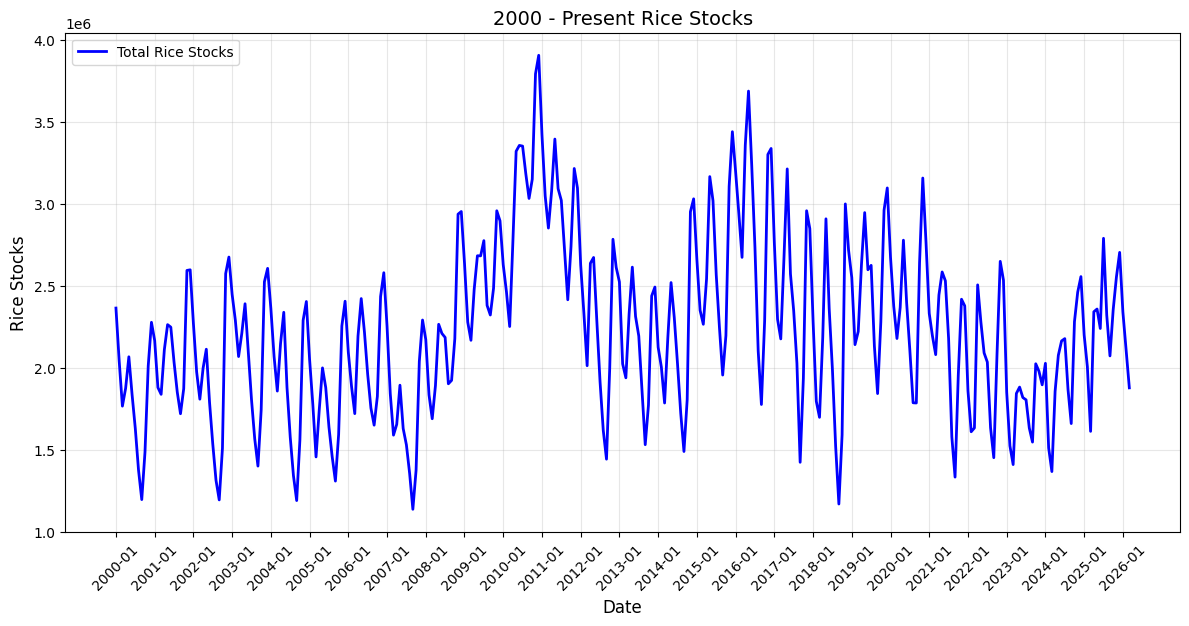

In [ ]:
# 1. Formatting the date range for the legend
start_date = data.index.min()
end_date = data.index.max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

data['date'] = data.index.strftime('%Y-%m')

# Total rice stocks
plt.plot(data['date'], data['stock_total'], label=f'Total Rice Stocks', color='blue', linewidth=2)

# 3. Aesthetics
plt.title('2000 - Present Rice Stocks', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::12], rotation=45)
data = data.drop(columns=['date'])
plt.show()

### Household, Commercial, and NFA rice stock

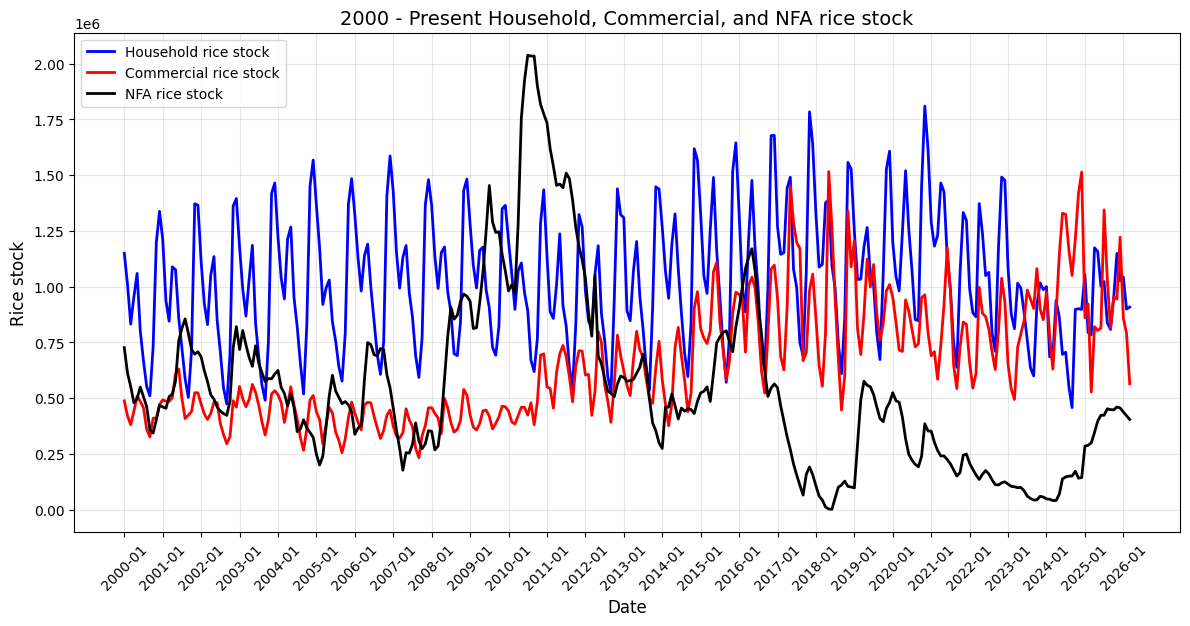

In [ ]:
# 2. Plotting
plt.figure(figsize=(12, 6))

data['date'] = data.index.strftime('%Y-%m')

# Adjust alpha to highlight feature
plt.plot(data['date'], data['stock_household'], label=f'Household rice stock', color='blue', linewidth=2, alpha=1)

plt.plot(data['date'], data['stock_commercial'], label=f'Commercial rice stock', color='red', linewidth=2, alpha=1)

plt.plot(data['date'], data['stock_nfa'], label=f'NFA rice stock', color='black', linewidth=2, alpha=1)

# 3. Aesthetics
plt.title('2000 - Present Household, Commercial, and NFA rice stock', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice stock', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::12], rotation=45)
data = data.drop(columns=['date'])
plt.show()

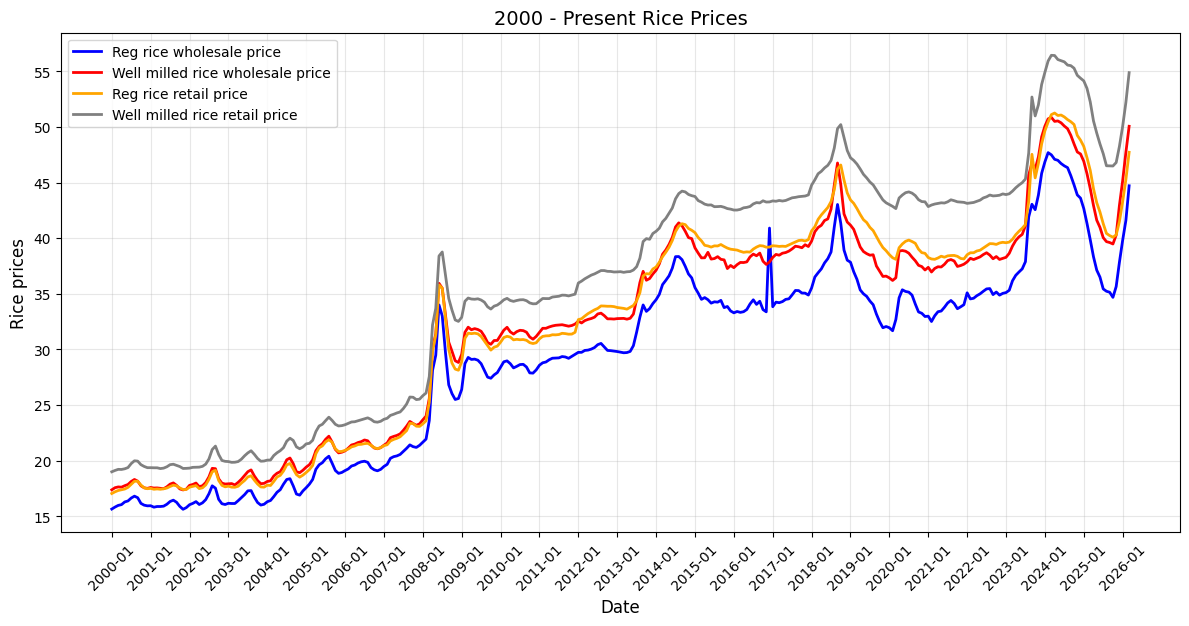

In [ ]:
# 2. Plotting
plt.figure(figsize=(12, 6))

data['date'] = data.index.strftime('%Y-%m')

# Regular wholesale rice price
plt.plot(data['date'], data['regular_wholesale_price'], label=f'Reg rice wholesale price', color='blue', linewidth=2)

plt.plot(data['date'], data['milled_wholesale_price'], label=f'Well milled rice wholesale price', color='red', linewidth=2)

plt.plot(data['date'], data['regular_retail_price'], label=f'Reg rice retail price', color='orange', linewidth=2)

plt.plot(data['date'], data['milled_retail_price'], label=f'Well milled rice retail price', color='gray', linewidth=2)

# 3. Aesthetics
plt.title('2000 - Present Rice Prices', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice prices', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::12], rotation=45)
plt.show()

### Visualizing lags

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

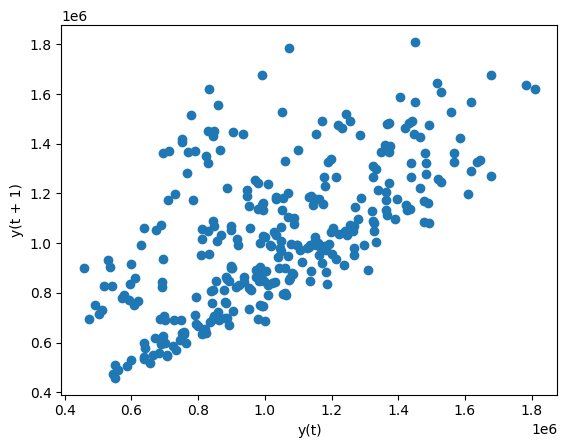

In [ ]:
''' lag = number of month lagged '''
lag_plot(data['stock_household'], lag=1)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

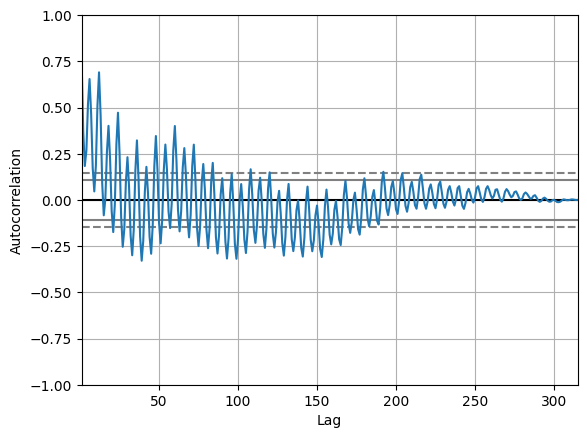

In [ ]:
pd.plotting.autocorrelation_plot(data['stock_total'])

## Feature Engineering

### Shift features by N months function

In [9]:
def shift_all_features(data, months_shift):
  data_shift = data.drop(columns=['stock_total', 'is_lean_month'])
  data_shift.index = pd.to_datetime(data['date']).dt.to_period('M')
  data_shift = data_shift.drop(columns=['date'])

  data_shift = data_shift.shift(periods=months_shift, freq="infer")
  stock_total = data[['date', 'stock_total']]
  stock_total.index = pd.to_datetime(stock_total['date']).dt.to_period('M')
  stock_total = stock_total.drop(columns=['date'])

  data_shift = pd.concat([stock_total, data_shift], axis=1)

  data_shift = data_shift[months_shift:]

  data_shift, remaining_features = data_shift[0:-12], data_shift[-12:]

  return data_shift, remaining_features

def shift_feature(col, months_shift):
  return

def whole_data_show(data):
  with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
      print(data)

### features shift 6 months

In [ ]:
#total_stock, remaining_features = shift_all_features(data, 6)

### features shift 12 months

In [ ]:
#total_stock, remaining_features = shift_all_features(data, 12)

### rolling average (rol_[stock type])

In [10]:
exp_data = data

In [11]:
exp_data['rol_stock_total'] = exp_data['stock_total'].rolling(window=12, closed='left').mean()
exp_data['rol_stock_household'] = exp_data['stock_household'].rolling(window=12, closed='left').mean()
exp_data['rol_stock_commercial'] = exp_data['stock_commercial'].rolling(window=12, closed='left').mean()
exp_data['rol_stock_nfa'] = exp_data['stock_nfa'].rolling(window=12, closed='left').mean()

### price percentage difference (price_delta)

### shift feature 12 months

In [12]:
total_stock, remaining_features = shift_all_features(exp_data, 12)

In [13]:
total_stock = total_stock[12:]

In [14]:
total_stock

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,rol_stock_total
date,,,,,,,,,
2002-01,2270700.00,1212600.00,492400.00,461100.00,15.95,17.59,17.51,19.37,1.826767e+06
2002-02,1975200.00,937700.00,487100.00,454600.00,15.82,17.54,17.43,19.36,1.810233e+06
2002-03,1808200.00,845300.00,485600.00,506900.00,15.88,17.55,17.46,19.36,1.796658e+06
2002-04,1997200.00,1088900.00,502700.00,519100.00,15.88,17.51,17.43,19.29,1.802667e+06
2002-05,2113200.00,1076300.00,610100.00,576900.00,15.91,17.48,17.47,19.33,1.822317e+06
...,...,...,...,...,...,...,...,...,...
2025-11,2554138.42,901206.77,1418557.09,141677.67,43.89,47.75,49.24,54.64,1.905055e+06
2025-12,2704507.01,898293.46,1514261.25,144047.67,43.60,47.57,48.81,54.38,1.945295e+06
2026-01,2341155.06,1054600.02,860797.99,284812.00,42.66,46.91,48.25,54.14,2.000364e+06


### Holdout size (final test set)

In [15]:
holdout_size = 24

### Log transformation - (y - target variable [stock_total]) - (NOT NEEDED)

<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2350/3767889977.py:9: SyntaxWarning: invalid escape sequence '\m'
  plt.legend(['Normal dist. ($\mu=$ {:.2f} and $\sigma=$ {:.2f} )'.format(mu, sigma)],
/tmp/ipykernel_2350/3767889977.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(total_stock['stock_total'] , fit=norm)



 mu = 2251879.77 and sigma = 544068.48



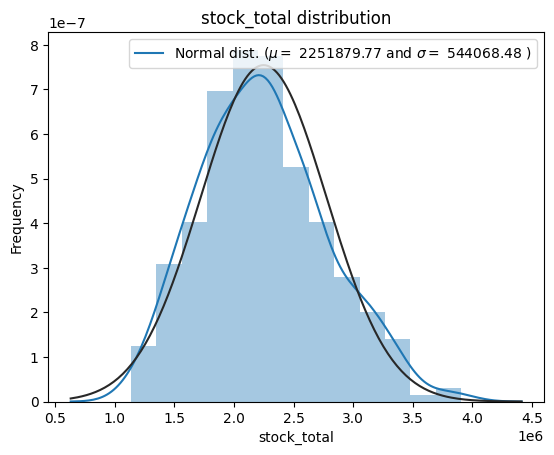

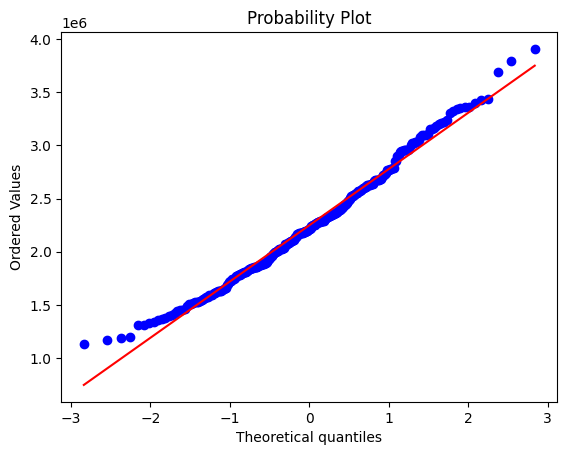

In [ ]:
'''
from scipy import stats
from scipy.stats import norm, skew #for some statistics

sns.distplot(total_stock['stock_total'] , fit=norm)

(mu, sigma) = norm.fit(total_stock['stock_total'].iloc[:-holdout_size])
print( '\n mu = {:.2f} and sigma = {:.2f}\n'.format(mu, sigma))

plt.legend(['Normal dist. ($\mu=$ {:.2f} and $\sigma=$ {:.2f} )'.format(mu, sigma)],
            loc='best')
plt.ylabel('Frequency')
plt.title('stock_total distribution')

#Get also the QQ-plot
fig = plt.figure()
res = stats.probplot(total_stock['stock_total'], plot=plt)
plt.show()
'''

<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2350/2818442806.py:8: SyntaxWarning: invalid escape sequence '\m'
  plt.legend(['Normal dist. ($\mu=$ {:.2f} and $\sigma=$ {:.2f} )'.format(mu, sigma)],
/tmp/ipykernel_2350/2818442806.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(total_stock['stock_total'] , fit=norm)



 mu = 14.60 and sigma = 0.25



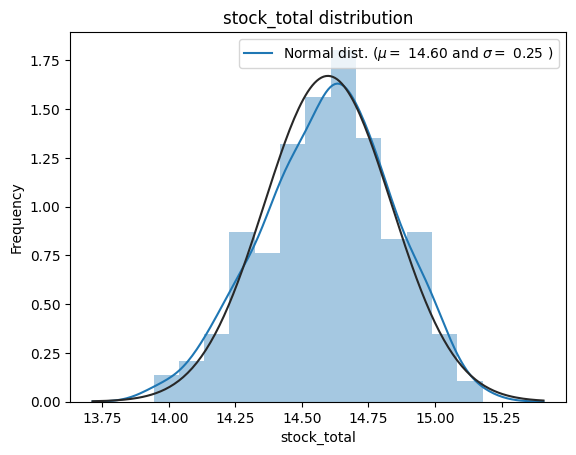

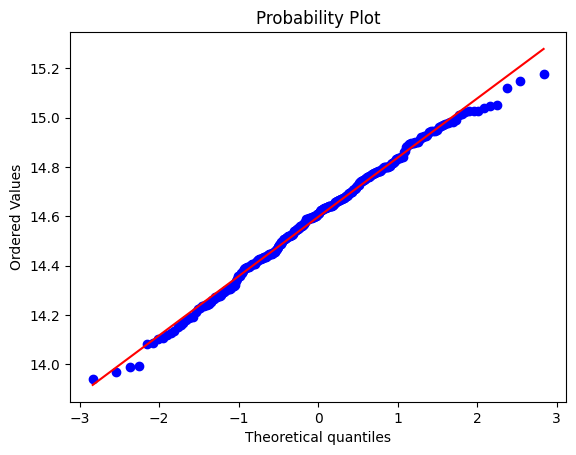

In [ ]:
'''
total_stock["stock_total"] = np.log1p(total_stock["stock_total"])

sns.distplot(total_stock['stock_total'] , fit=norm)

(mu, sigma) = norm.fit(total_stock['stock_total'].iloc[:-holdout_size])
print( '\n mu = {:.2f} and sigma = {:.2f}\n'.format(mu, sigma))

plt.legend(['Normal dist. ($\mu=$ {:.2f} and $\sigma=$ {:.2f} )'.format(mu, sigma)],
            loc='best')
plt.ylabel('Frequency')
plt.title('stock_total distribution')

fig = plt.figure()
res = stats.probplot(total_stock['stock_total'], plot=plt)
plt.show()
'''

### Log transformation - features - (NOT NEEDED)

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2350/370779591.py:12: SyntaxWarning: invalid escape sequence '\m'
  plt.legend(['Normal dist. ($\mu=$ {:.2f} and $\sigma=$ {:.2f} )'.format(mu, sigma)],
/tmp/ipykernel_2350/370779591.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(total_stock[feat] , fit=norm)



 mu = 614020.51 and sigma = 242548.90



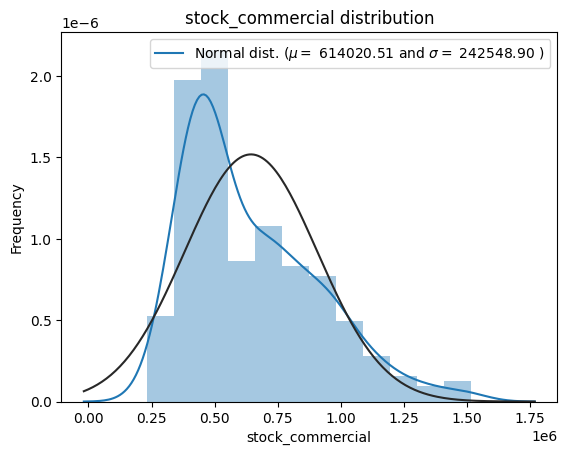

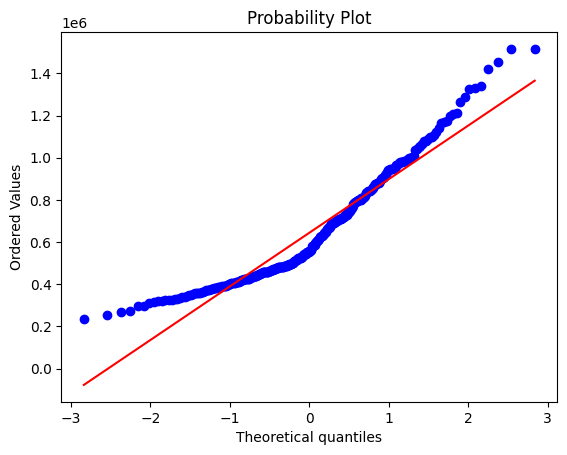

In [ ]:
'''
Features:
stock_household, stock_commerical, stock_nfa, regular_wholesale_price,
milled_wholesale_price,	regular_retail_price,	milled_retail_price, is_lean_month
'''

'''
feat = 'stock_commercial'
sns.distplot(total_stock[feat] , fit=norm)

(mu, sigma) = norm.fit(total_stock[feat].iloc[:-holdout_size])
print( '\n mu = {:.2f} and sigma = {:.2f}\n'.format(mu, sigma))

plt.legend(['Normal dist. ($\mu=$ {:.2f} and $\sigma=$ {:.2f} )'.format(mu, sigma)],
            loc='best')
plt.ylabel('Frequency')
plt.title(f'{feat} distribution')

#Get also the QQ-plot
fig = plt.figure()
res = stats.probplot(total_stock[feat], plot=plt)
plt.show()
'''

### Final dataset and train test split

In [17]:
total_stock, remaining_features = add_lean_months(total_stock), add_lean_months(remaining_features)
test = total_stock['stock_total'].iloc[-holdout_size:]

## Check correlation

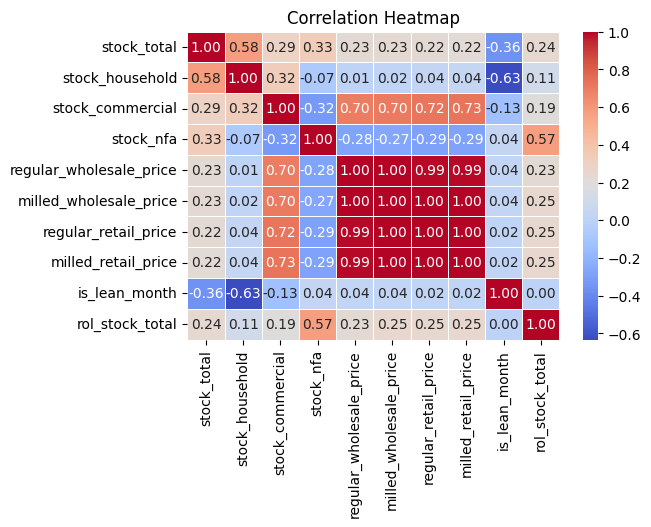

In [18]:
# Calculate correlation matrix
corr_matrix = total_stock[['stock_total', 'stock_household', 'stock_commercial',
                          'stock_nfa', 'regular_wholesale_price', 'milled_wholesale_price',
                          'regular_retail_price', 'milled_retail_price', 'is_lean_month', 'rol_stock_total']].corr()

# Create the plot
plt.figure(figsize=(6,  4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show('correlation_plot.png')
# print("correlation_plot.png saved")

## Model Training (not used)

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from xgboost import XGBRegressor

# 1. FIT HOLT-WINTERS (Univariate)
# We only use the 'target' column here
hw_model = ExponentialSmoothing(data['stock_total'], trend='add', seasonal='add', seasonal_periods=12).fit()
data['hw_basis'] = hw_model.fittedvalues

In [ ]:
data

,date,stock_total,stock_household,stock_commercial,stock_nfa,price_regular,price_milled,is_lean_month,stock_commerical,hw_basis
0,2000-01,2364500.00,1149700.00,488200.00,726600.0,15.65,17.38,0,488200.00,2.184590e+06
1,2000-02,2042300.00,1009500.00,420600.00,612200.0,15.83,17.57,0,420600.00,2.121176e+06
2,2000-03,1765700.00,832200.00,381000.00,552500.0,15.98,17.64,0,381000.00,1.936581e+06
3,2000-04,1874900.00,954400.00,441200.00,479300.0,16.05,17.62,0,441200.00,2.098021e+06
4,2000-05,2067000.00,1059500.00,509600.00,497900.0,16.29,17.75,0,509600.00,2.066639e+06
...,...,...,...,...,...,...,...,...,...,...
307,2025-08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,1,1030751.52,2.229756e+06
308,2025-09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,1,815346.38,2.089261e+06
309,2025-10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,0,954908.93,2.607736e+06
310,2025-11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,0,944142.43,2.881995e+06


In [ ]:
# 2. CALCULATE RESIDUALS
# This is what XGBoost will try to solve
data['residuals'] = data['stock_total'] - data['hw_basis']
data

,date,stock_total,stock_household,stock_commercial,stock_nfa,price_regular,price_milled,is_lean_month,stock_commerical,hw_basis,residuals
0,2000-01,2364500.00,1149700.00,488200.00,726600.0,15.65,17.38,0,488200.00,2.184590e+06,179909.819425
1,2000-02,2042300.00,1009500.00,420600.00,612200.0,15.83,17.57,0,420600.00,2.121176e+06,-78876.380520
2,2000-03,1765700.00,832200.00,381000.00,552500.0,15.98,17.64,0,381000.00,1.936581e+06,-170881.451121
3,2000-04,1874900.00,954400.00,441200.00,479300.0,16.05,17.62,0,441200.00,2.098021e+06,-223120.858609
4,2000-05,2067000.00,1059500.00,509600.00,497900.0,16.29,17.75,0,509600.00,2.066639e+06,360.555677
...,...,...,...,...,...,...,...,...,...,...,...
307,2025-08,2321437.85,837944.33,1030751.52,452742.0,35.23,39.69,1,1030751.52,2.229756e+06,91682.075134
308,2025-09,2072433.22,808431.85,815346.38,448655.0,35.14,39.61,1,815346.38,2.089261e+06,-16827.552357
309,2025-10,2354896.32,952087.39,954908.93,447900.0,34.68,39.48,0,954908.93,2.607736e+06,-252839.707633
310,2025-11,2554138.42,1149260.99,944142.43,460735.0,35.65,40.28,0,944142.43,2.881995e+06,-327856.781383


In [ ]:
# 3. TRAIN XGBOOST ON FEATURES
# Features (X) can be anything: price, promo, weather, etc.
X = data[['stock_commercial', 'stock_household', 'stock_nfa', 'price_regular',
          'price_milled', 'is_lean_month', 'hw_basis']]
y = data['residuals']

xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, enable_categorical=True)
xgb_model.fit(X, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# 4. PREDICT & RECOMPOSE
# Final Forecast = HW Prediction + XGBoost's correction
hw_future = hw_model.forecast(steps=12)
xgb_correction = xgb_model.predict(X_future)

final_forecast = hw_future + xgb_correction


NameError: name 'X_future' is not defined

### Dataset split and cross validation


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

In [ ]:
# 2. Initialize TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=8)
rmse_scores = []

In [ ]:
print(f"{'Fold':<10} | {'Train Size':<12} | {'Test Size':<10} | {'RMSE'}")
print("-" * 50)
for i, (train_index, test_index) in enumerate(tscv.split(data)):
    train, test = data.iloc[train_index], data.iloc[test_index]

    # 4. Fit Holt-Winters Model
    # Note: Adjust trend, seasonal, and seasonal_periods based on your data
    model = ExponentialSmoothing(
        train['stock_total'],
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
# 5. Forecast
    predictions = model.forecast(len(test))

# 6. Evaluate
    rmse = np.sqrt(mean_squared_error(test['stock_total'], predictions))
    rmse_scores.append(rmse)

    print(f"{i+1:<10} | {len(train):<12} | {len(test):<10} | {rmse:.4f}")

Fold       | Train Size   | Test Size  | RMSE
--------------------------------------------------
1          | 35           | 35         | 2763081.2278
2          | 70           | 35         | 248162.7070
3          | 105          | 35         | 539276.2944
4          | 140          | 35         | 1282441.8959
5          | 175          | 35         | 483710.1845
6          | 210          | 35         | 328878.7549
7          | 245          | 35         | 313649.4908
8          | 280          | 35         | 638305.6821


In [ ]:
print("-" * 50)
print(f"Average RMSE: {np.mean(rmse_scores):.4f}")

--------------------------------------------------
Average RMSE: 357315.6441


## SARIMA Testing

### Augmented Dickey-Fuller test

In [19]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 15.2 MB/s eta 0:00:00


In [20]:
import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Automatically determine 'd' and 'D' using ADF and other tests
d_order = pm.arima.ndiffs(total_stock['stock_total'], test='adf')          # test = 'adf' working
D_order = pm.arima.nsdiffs(total_stock['stock_total'], m=12, test='ocsb')  # test = 'ocsb' working

print(f"Recommended non-seasonal differencing (d): {d_order}")
print(f"Recommended seasonal differencing (D): {D_order}")

# 2. Fit the SARIMA model using those parameters
# Example order: (p, d, q) x (P, D, Q, s)
sarima = SARIMAX(total_stock['stock_total'].iloc[:-holdout_size],
                order=(1, d_order, 1),
                seasonal_order=(1, D_order, 1, 12))

sarima_model = sarima.fit()
print(sarima_model.summary())

Recommended non-seasonal differencing (d): 0
Recommended seasonal differencing (D): 0
                                     SARIMAX Results                                      
Dep. Variable:                        stock_total   No. Observations:                  267
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 12)   Log Likelihood               -3691.999
Date:                            Thu, 04 Jun 2026   AIC                           7393.998
Time:                                    06:01:48   BIC                           7411.934
Sample:                                01-31-2002   HQIC                          7401.203
                                     - 03-31-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9273      0

In [21]:
sarima_forecast = sarima_model.forecast(steps=holdout_size)
sarima_forecast

,predicted_mean
2024-04,1.824115e+06
2024-05,1.859405e+06
2024-06,1.744070e+06
2024-07,1.666601e+06
2024-08,1.399388e+06
2024-09,1.279370e+06
2024-10,1.768699e+06
2024-11,2.006445e+06
2024-12,1.921870e+06
2025-01,1.731333e+06


In [22]:
# 5. Test against the Hold-out Set
sarima_mape = mean_absolute_percentage_error(test, sarima_forecast)
sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = root_mean_squared_error(test, sarima_forecast)
sarima_r2 = r2_score(test, sarima_forecast)

print(f"Final Model MAPE: {round(sarima_mape, 4)}\n"
f"Final Model MAE: {round(sarima_mae, 4)}\n"
f"Final Model RMSE: {round(sarima_rmse, 4)}\n"
f"Final Model R2: {round(sarima_r2, 4)}")

Final Model MAPE: 0.2681
Final Model MAE: 601676.4923
Final Model RMSE: 651255.004
Final Model R2: -3.882


## Holt-winters and XGBoost model


### Holt-Winters
### Time series cross-validation and Hyperparameter tuning (Expanding Window)

In [23]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def tscv_holt_winters(data, seasonal_periods, param_grid, splits, train_each_fold):
    tscv = TimeSeriesSplit(n_splits=splits, max_train_size=train_each_fold)

    # Generate all combinations of alpha, beta, and gamma
    keys, values = zip(*param_grid.items())
    combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

    results_list = []

    for combo in combinations:
        fold_mapes = []
        fold_mae = []
        fold_rmse = []
        fold_r2 = []
        train_size = []
        test_size = []

        # Cross-validation on the train_val subset
        for train_index, test_index in tscv.split(train_val):
            train, test = train_val.iloc[train_index], train_val.iloc[test_index]

            try:
                model = ExponentialSmoothing(
                    train,
                    trend='add',
                    seasonal='add',
                    seasonal_periods=seasonal_periods
                ).fit(
                    smoothing_level=combo['alpha'],
                    smoothing_trend=combo['beta'],
                    smoothing_seasonal=combo['gamma'],
                    optimized=False
                )

                forecast = model.forecast(len(test))
                mape = mean_absolute_percentage_error(test, forecast)
                mae = mean_absolute_error(test, forecast)
                rmse = root_mean_squared_error(test, forecast)
                r2 = r2_score(test, forecast)

                fold_mae.append(mae)
                fold_rmse.append(rmse)
                fold_mapes.append(mape)
                fold_r2.append(r2)

                train_input = len(train)
                train_size.append(train_input)
                test_input = len(test)
                test_size.append(test_input)
            except Exception:
                # Handle cases where parameters lead to non-convergence
                continue

        # Store average performance and parameters for the list
        if fold_mapes:
            avg_mape = np.mean(fold_mapes)
            avg_mae = np.mean(fold_mae)
            avg_rmse = np.mean(fold_rmse)
            avg_r2 = np.mean(fold_r2)
            mape_variance = np.var(fold_mapes)
            results_list.append({
                "alpha": combo['alpha'],
                "beta": combo['beta'],
                "gamma": combo['gamma'],
                "mape_variance" : round(mape_variance, 8),
                "avg_MAPE": round((avg_mape), 4),
                "avg_MAE": round((avg_mae), 4),
                "avg_RMSE": round((avg_rmse), 4),
                "avg_R2": round((avg_r2), 4),
                "fold_details": [(tr_size, ts_size, round(mape, 4))
                  for tr_size, ts_size, mape in zip(train_size, test_size, fold_mapes)]
            })
    # return sorted(results_list, key=lambda x: x['mape_variance'])
    return results_list

In [24]:
# parameters to be tested
params = {
  'alpha': [0.1, 0.3, 0.5, 0.7, 0.9],
  'beta': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9],
  'gamma': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
}

# final model test size
# holdout_size = 24
train_val = total_stock['stock_total'].iloc[:-holdout_size]

In [25]:
''''
tscv_holt_winters(1, 2, 3, 4, 5) parameters:
  1 - training set
  2 - number of seasonal period - 12(yearly) default
  3 - hyperparameters (grid)
  4 - number of folds (number of cross-validation)
  5 - number of maximum training set (set to None for expanding window approach)
'''

models_exp = tscv_holt_winters(train_val, 12, params, 5, None)
# models_rol = tscv_holt_winters(train_val, 12, params, 5, 51)

In [26]:
avg_mape_models = sorted(models_exp, key=lambda x: x['avg_MAPE'])
# sorted(models, key=lambda x: x['mape_variance'])

top_lowest_mape = [x for x in avg_mape_models[:10]]
for i in top_lowest_mape:
  print(i)

{'alpha': 0.5, 'beta': 0.05, 'gamma': 0.5, 'mape_variance': 0.00232208, 'avg_MAPE': 0.1686, 'avg_MAE': 372330.264, 'avg_RMSE': 478706.4492, 'avg_R2': -0.0184, 'fold_details': [(47, 44, 0.1335), (91, 44, 0.2617), (135, 44, 0.1567), (179, 44, 0.1295), (223, 44, 0.1615)]}
{'alpha': 0.7, 'beta': 0.01, 'gamma': 0.5, 'mape_variance': 0.0013278, 'avg_MAPE': 0.1774, 'avg_MAE': 373960.4914, 'avg_RMSE': 460329.0882, 'avg_R2': 0.0456, 'fold_details': [(47, 44, 0.143), (91, 44, 0.2322), (135, 44, 0.1479), (179, 44, 0.1542), (223, 44, 0.2097)]}
{'alpha': 0.5, 'beta': 0.01, 'gamma': 0.3, 'mape_variance': 0.00173097, 'avg_MAPE': 0.1787, 'avg_MAE': 379972.6284, 'avg_RMSE': 461266.2692, 'avg_R2': 0.0456, 'fold_details': [(47, 44, 0.1477), (91, 44, 0.2302), (135, 44, 0.1172), (179, 44, 0.2137), (223, 44, 0.1848)]}
{'alpha': 0.9, 'beta': 0.01, 'gamma': 0.5, 'mape_variance': 0.00237813, 'avg_MAPE': 0.1787, 'avg_MAE': 385758.7321, 'avg_RMSE': 480304.1285, 'avg_R2': -0.0385, 'fold_details': [(47, 44, 0.1377

### Final Holt-winters model

In [27]:
''' The parameters with the lowest average mape / mape variance across all folds is selected
for the final model.  '''
best_model_onavg = top_lowest_mape[0]
print(f"Best Parameters: level: {best_model_onavg['alpha']} | "
      f"trend: {best_model_onavg['beta']} | seasonal: {best_model_onavg['gamma']}")

# 3. Prepare the Final Datasets
train_val = total_stock['stock_total'].iloc[:-holdout_size]
test = total_stock['stock_total'].iloc[-holdout_size:]

# 4. Train the Final Model on the entire train_val set
hw_model = ExponentialSmoothing(
    train_val,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
).fit(
    smoothing_level=best_model_onavg['alpha'],
    smoothing_trend=best_model_onavg['beta'],
    smoothing_seasonal=best_model_onavg['gamma'],
    optimized=False
)

Best Parameters: level: 0.5 | trend: 0.05 | seasonal: 0.5


In [28]:
hw_forecast = hw_model.forecast(holdout_size)
# hw_forecast = np.expm1(hw_forecast)

# 5. Test against the Hold-out Set
hw_mape = mean_absolute_percentage_error(test, hw_forecast)
hw_mae = mean_absolute_error(test, hw_forecast)
hw_rmse = root_mean_squared_error(test, hw_forecast)
hw_r2 = r2_score(test, hw_forecast)

print(f"Final Model MAPE: {round(hw_mape, 4)}\n"
f"Final Model MAE: {round(hw_mae, 4)}\n"
f"Final Model RMSE: {round(hw_rmse, 4)}\n"
f"Final Model R2: {round(hw_r2, 4)}")

Final Model MAPE: 0.2324
Final Model MAE: 521655.0595
Final Model RMSE: 587335.2924
Final Model R2: -2.9707


### Visualization: Holt-winters

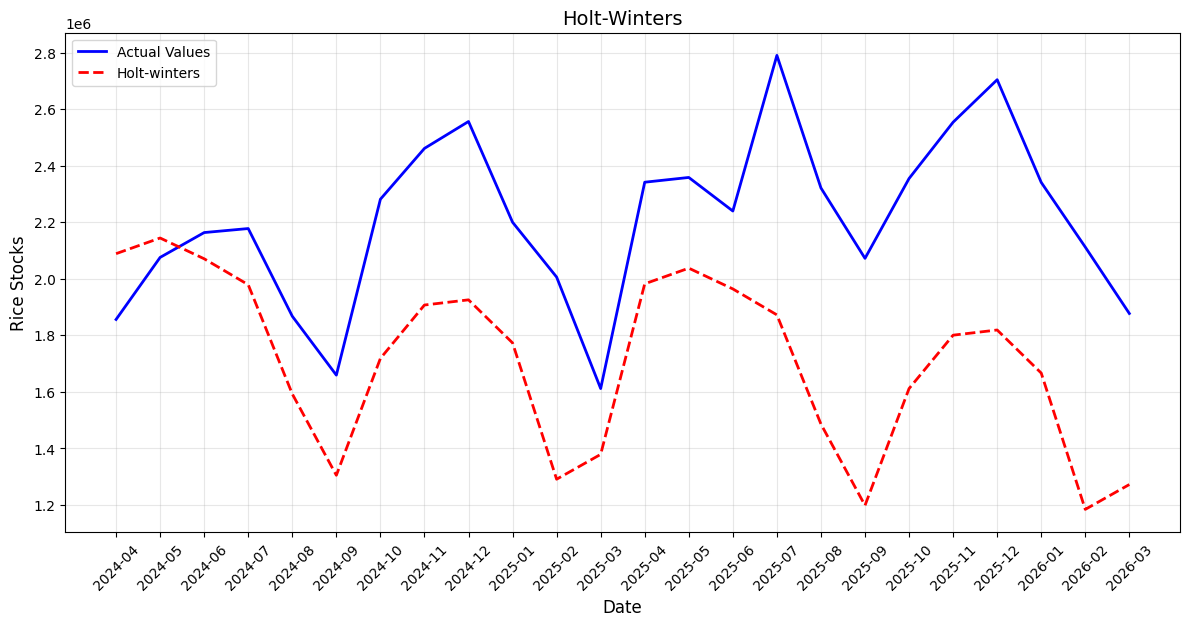

In [29]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Actual Values', color='blue', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], hw_forecast, label=f'Holt-winters', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

### Visualization Holt-winters fitted values

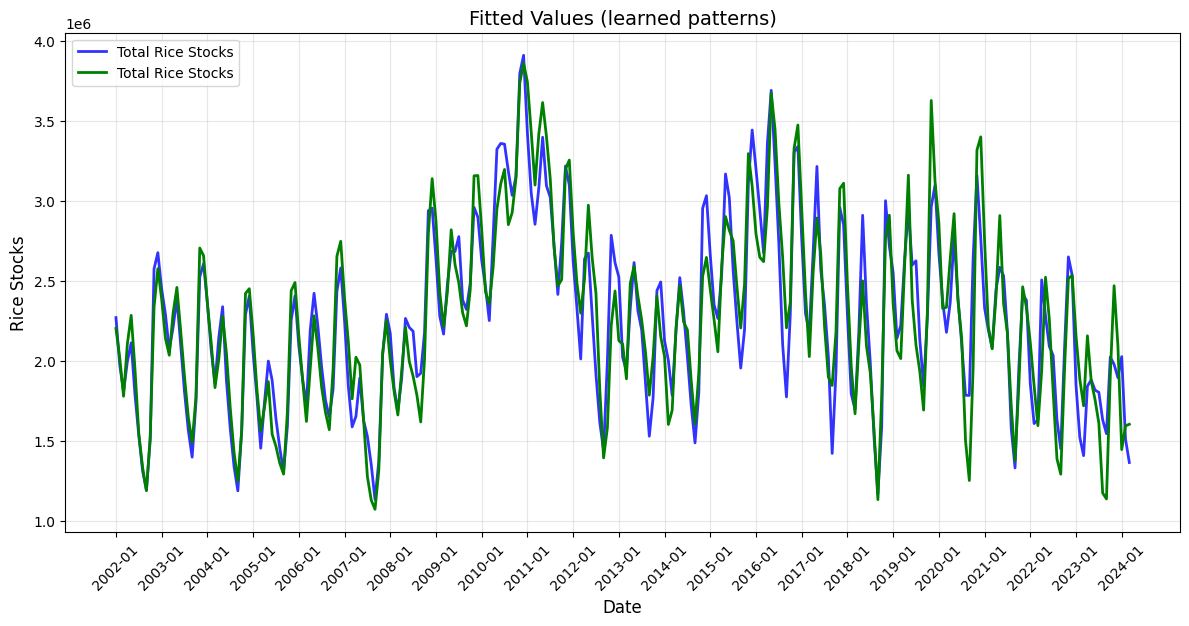

In [30]:
# 1. Formatting the date range for the legend
total_stock['date'] = total_stock.index.strftime('%Y-%m')
start_date = total_stock['date'].iloc[:-holdout_size].min()
end_date = total_stock['date'].iloc[:-holdout_size].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Total rice stocks
plt.plot(total_stock['date'].iloc[:-holdout_size], total_stock['stock_total'].iloc[:-holdout_size],
         label=f'Total Rice Stocks', color='blue', linewidth=2, alpha=0.8)

plt.plot(total_stock['date'].iloc[:-holdout_size:], hw_model.fittedvalues, label=f'Total Rice Stocks',
         color='green', linewidth=2)

# 3. Aesthetics
plt.title('Fitted Values (learned patterns)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(total_stock['date'].iloc[:-holdout_size][::12], rotation=45)
# total_stock = total_stock.drop(columns=['date'])
plt.show()

### XGBoost

In [31]:
whole_data = pd.concat([total_stock, remaining_features], axis=0)
total_stock

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,rol_stock_total,is_lean_month,date
date,,,,,,,,,,,
2002-01,2270700.00,1212600.00,492400.00,461100.00,15.95,17.59,17.51,19.37,1.826767e+06,0,2002-01
2002-02,1975200.00,937700.00,487100.00,454600.00,15.82,17.54,17.43,19.36,1.810233e+06,0,2002-02
2002-03,1808200.00,845300.00,485600.00,506900.00,15.88,17.55,17.46,19.36,1.796658e+06,0,2002-03
2002-04,1997200.00,1088900.00,502700.00,519100.00,15.88,17.51,17.43,19.29,1.802667e+06,0,2002-04
2002-05,2113200.00,1076300.00,610100.00,576900.00,15.91,17.48,17.47,19.33,1.822317e+06,0,2002-05
...,...,...,...,...,...,...,...,...,...,...,...
2025-11,2554138.42,901206.77,1418557.09,141677.67,43.89,47.75,49.24,54.64,1.905055e+06,0,2025-11
2025-12,2704507.01,898293.46,1514261.25,144047.67,43.60,47.57,48.81,54.38,1.945295e+06,0,2025-12
2026-01,2341155.06,1054600.02,860797.99,284812.00,42.66,46.91,48.25,54.14,2.000364e+06,0,2026-01


In [33]:
data_xgb = total_stock.iloc[:-holdout_size]
data_xgb['residuals'] = data_xgb['stock_total'] - hw_model.fittedvalues
data_xgb

/tmp/ipykernel_790/3190794251.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_xgb['residuals'] = data_xgb['stock_total'] - hw_model.fittedvalues


,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,rol_stock_total,is_lean_month,date,residuals
date,,,,,,,,,,,,
2002-01,2270700.00,1212600.00,492400.00,461100.0,15.95,17.59,17.51,19.37,1.826767e+06,0,2002-01,67538.631629
2002-02,1975200.00,937700.00,487100.00,454600.0,15.82,17.54,17.43,19.36,1.810233e+06,0,2002-02,-42526.889875
2002-03,1808200.00,845300.00,485600.00,506900.0,15.88,17.55,17.46,19.36,1.796658e+06,0,2002-03,28451.438286
2002-04,1997200.00,1088900.00,502700.00,519100.0,15.88,17.51,17.43,19.29,1.802667e+06,0,2002-04,-110234.225257
2002-05,2113200.00,1076300.00,610100.00,576900.0,15.91,17.48,17.47,19.33,1.822317e+06,0,2002-05,-171606.618064
...,...,...,...,...,...,...,...,...,...,...,...,...
2023-11,1978558.36,1491320.00,1038010.00,120480.0,34.88,38.09,39.57,43.86,1.997904e+06,0,2023-11,-491025.211264
2023-12,1895782.56,1476280.00,933010.00,125300.0,35.04,38.19,39.63,43.98,2.017186e+06,0,2023-12,-199267.365410
2024-01,2027180.48,1083610.00,651930.00,114910.0,35.11,38.28,39.59,43.92,2.030248e+06,0,2024-01,580417.901920


### Residuals visualization

/tmp/ipykernel_790/705292800.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_xgb['date'] = data_xgb.index.strftime('%Y-%m')


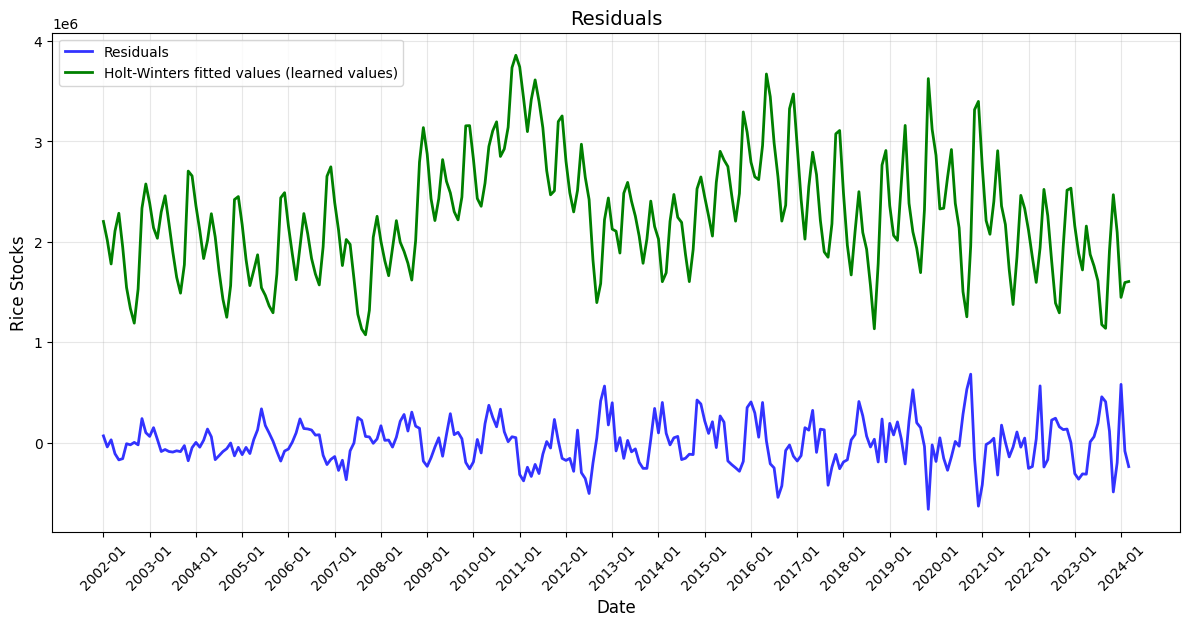

In [47]:
# 1. Formatting the date range for the legend
data_xgb['date'] = data_xgb.index.strftime('%Y-%m')
start_date = data_xgb['date'].iloc[:-holdout_size].min()
end_date = data_xgb['date'].iloc[:-holdout_size].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Residuals
plt.plot(data_xgb['date'], data_xgb['residuals'],
         label=f'Residuals', color='blue', linewidth=2, alpha=0.8)

plt.plot(data_xgb['date'], hw_model.fittedvalues, label=f'Holt-Winters fitted values (learned values)',
         color='green', linewidth=2)

# 3. Aesthetics
plt.title('Residuals', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data_xgb['date'][::12], rotation=45)
# data_xgb = data_xgb.drop(columns=['date'])
plt.show()

In [48]:
data_xgb

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,rol_stock_total,is_lean_month,date,residuals
date,,,,,,,,,,,,
2002-01,2270700.00,1212600.00,492400.00,461100.0,15.95,17.59,17.51,19.37,1.826767e+06,0,2002-01,67538.631629
2002-02,1975200.00,937700.00,487100.00,454600.0,15.82,17.54,17.43,19.36,1.810233e+06,0,2002-02,-42526.889875
2002-03,1808200.00,845300.00,485600.00,506900.0,15.88,17.55,17.46,19.36,1.796658e+06,0,2002-03,28451.438286
2002-04,1997200.00,1088900.00,502700.00,519100.0,15.88,17.51,17.43,19.29,1.802667e+06,0,2002-04,-110234.225257
2002-05,2113200.00,1076300.00,610100.00,576900.0,15.91,17.48,17.47,19.33,1.822317e+06,0,2002-05,-171606.618064
...,...,...,...,...,...,...,...,...,...,...,...,...
2023-11,1978558.36,1491320.00,1038010.00,120480.0,34.88,38.09,39.57,43.86,1.997904e+06,0,2023-11,-491025.211264
2023-12,1895782.56,1476280.00,933010.00,125300.0,35.04,38.19,39.63,43.98,2.017186e+06,0,2023-12,-199267.365410
2024-01,2027180.48,1083610.00,651930.00,114910.0,35.11,38.28,39.59,43.92,2.030248e+06,0,2024-01,580417.901920


### Correlation matrix residuals feature included

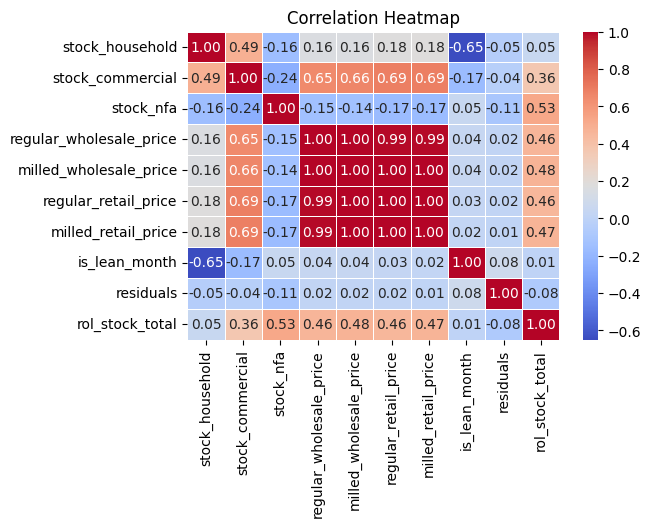

In [49]:
# Calculate correlation matrix
corr_matrix_resid = data_xgb[['stock_household', 'stock_commercial',
                          'stock_nfa', 'regular_wholesale_price', 'milled_wholesale_price',
                          'regular_retail_price', 'milled_retail_price', 'is_lean_month', 'residuals', 'rol_stock_total']].corr()

# Create the plot
plt.figure(figsize=(6,  4))
sns.heatmap(corr_matrix_resid, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show('correlation_plot.png')

### experiment 1: x - features, y - residuals

In [50]:
X_train = data_xgb.drop(columns=['stock_total', 'residuals'])
y_train = data_xgb['residuals']

if 'date' in X_train.columns:
  X_train = X_train.drop(columns=['date'])

'''
X_test = total_stock.drop(columns=['stock_total']).iloc[:-holdout_size]
y_test = total_stock.drop
'''
X_train['stock_commercial'] = X_train['stock_commercial'].astype('float64')
X_train['stock_household'] = X_train['stock_household'].astype('float64')
X_train['stock_nfa'] = X_train['stock_nfa'].astype('float64')
X_train['regular_wholesale_price'] = X_train['regular_wholesale_price'].astype('float64')
X_train['milled_wholesale_price'] = X_train['milled_wholesale_price'].astype('float64')
X_train['regular_retail_price'] = X_train['regular_retail_price'].astype('float64')
X_train['milled_retail_price'] = X_train['milled_retail_price'].astype('float64')
X_train['is_lean_month'] = X_train['is_lean_month'].astype('int')
# y_train['residuals'] = y_train['residuals'].astype('float64')

# print(X_train['stock_total'].dtype)
print(X_train['stock_commercial'].dtype)
print(X_train['stock_household'].dtype)
print(X_train['stock_nfa'].dtype)
print(X_train['regular_wholesale_price'].dtype)
print(X_train['milled_wholesale_price'].dtype)
print(X_train['regular_retail_price'].dtype)
print(X_train['milled_retail_price'].dtype)
print(X_train['is_lean_month'].dtype)
print(y_train.dtype)

float64
float64
float64
float64
float64
float64
float64
int64
float64


### experiment 2: x - features, y - stock_total

In [ ]:
X_train = data_xgb.drop(columns=['date', 'stock_total', 'month'])
y_train = data_xgb['stock_total']

In [ ]:
X_train = X_train.drop(columns=['month'])
X_train

KeyError: "['month'] not found in axis"

### XGBoost hyperparameter tuning - Hybrid

In [86]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb_reg = XGBRegressor(objective='reg:squarederror', random_state=42,
                       enable_categorical=True, early_stopping=True)
'''
objective:

  reg:squarederror
  reg:absoluteerror
  reg:squaredlogerror
  reg:pseudohuberror
  reg:quantileerror
'''

param_grid = {
    'n_estimators': [10, 50, 100, 300, 500, 700],
    'max_depth': [2, 3, 5, 7],
    'learning_rate': [0.001, 0.01, 0.05, 0.1], # [0.001, 0.01, 0.05, 0.1]
    'subsample:': [0.2, 0.4],           # 'bagging'
    'min_child_weight': [3, 5, 7],
    'colsample_bytree': [0.5, 0.8],     # 'bagging'
    # 'gamma': [0.5, 1],
    'reg_lambda': [0.1, 0.5, 1, 2, 3]
    # 'reg_alpha': [0.01, 0.05, 0.1],
    # 'colsample_bylevel': [0.2, 0.4],    # 'bagging'
    # 'colsample_bynode': [0.2, 0.4]      # 'bagging'
}

# param_grid = {
#     'n_estimators': [100, 200, 500, 700, 900, 1000],
#     'max_depth': [3, 5, 7, 9, 10],
#     'learning_rate': [0.1, 0.8, 0.05, 0.02, 0.01],
#     'subsample': [1.0, 0.08, 0.07, 0.06, 0.05]
# }

# Initialize GridSearch
# refit=True ensures the model is retrained on the full dataset after CV

grid_search = GridSearchCV(
    estimator=xgb_reg,
    param_grid=param_grid,
    # cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_mean_absolute_error', # 'neg_mean_squared_error', 'r2'
    refit=True,
    n_jobs=-1,
)

In [52]:
# X_ext is your dataframe of external features
# grid_search.fit(X_train, y_train,
#     eval_set=[(X_train, y_train), (X_val, y_val)],
#     verbose=True)

grid_search.fit(X_train, y_train)

# The 'best_model' now contains the XGBoost model trained on the WHOLE dataset
xgb_hw_model = grid_search.best_estimator_

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:08:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
xgb_test_data = data.drop(columns=['stock_total'])

# xgb_test_data = xgb_test_data.drop(columns=['month'])
# xgb_test_data['stock_total'] = xgb_test_data['stock_total'].astype('float64')
xgb_test_data['stock_commercial'] = xgb_test_data['stock_commercial'].astype('float64')
xgb_test_data['stock_household'] = xgb_test_data['stock_household'].astype('float64')
xgb_test_data['stock_nfa'] = xgb_test_data['stock_nfa'].astype('float64')
xgb_test_data['regular_wholesale_price'] = xgb_test_data['regular_wholesale_price'].astype('float64')
xgb_test_data['milled_wholesale_price'] = xgb_test_data['milled_wholesale_price'].astype('float64')
xgb_test_data['regular_retail_price'] = xgb_test_data['regular_retail_price'].astype('float64')
xgb_test_data['milled_retail_price'] = xgb_test_data['milled_retail_price'].astype('float64')
xgb_test_data['is_lean_month'] = xgb_test_data['is_lean_month'].astype('int')

In [ ]:
xgb_test_data = xgb_test_data.drop(columns=['date'])

In [ ]:
xgb_test_data

,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,is_lean_month,rol_stock_toal,rol_stock_total
date,,,,,,,,,,
2000-01,1149700.00,488200.00,726600.00,15.65,17.38,17.05,19.00,0,NaN,NaN
2000-02,1009500.00,420600.00,612200.00,15.83,17.57,17.20,19.12,0,NaN,NaN
2000-03,832200.00,381000.00,552500.00,15.98,17.64,17.32,19.22,0,NaN,NaN
2000-04,954400.00,441200.00,479300.00,16.05,17.62,17.38,19.21,0,NaN,NaN
2000-05,1059500.00,509600.00,497900.00,16.29,17.75,17.45,19.27,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2025-11,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80,0,2.276316e+06,2.276316e+06
2025-12,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25,0,2.284040e+06,2.284040e+06
2026-01,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05,0,2.296366e+06,2.296366e+06


In [ ]:
xgb_test_data = xgb_test_data.reindex(columns =['stock_household', 'stock_commercial', 'stock_nfa', 'regular_wholesale_price',
                 'milled_wholesale_price', 'regular_retail_price', 'milled_retail_price', 'rol_stock_total', 'is_lean_month'])

In [57]:
# 1. Forecast the baseline with Holt-Winters
hw_forecast = hw_model.forecast(steps=len(test))

# 2. Forecast the residual correction with the retrained XGBoost
# test_features contains the external features for the future period
residual_correction = xgb_hw_model.predict(xgb_test_data[-24:])

# 3. Sum the components
final_hybrid_forecast = hw_forecast + residual_correction

In [53]:
xgb_test_data = total_stock[-holdout_size:]

In [54]:
if 'date' in xgb_test_data:
  xgb_test_data = xgb_test_data.drop(columns=['date'])
xgb_test_data

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,rol_stock_total,is_lean_month
date,,,,,,,,,,
2024-04,1856160.79,1015289.61,728730.70,99033.00,36.66,39.79,40.31,44.53,2.003675e+06,0
2024-05,2075770.81,993969.74,787970.99,100117.00,36.96,40.12,40.62,44.78,1.948418e+06,0
2024-06,2163673.78,884995.00,848107.90,85102.00,37.24,40.34,40.89,44.99,1.915260e+06,0
2024-07,2177878.72,758563.57,984761.41,60844.00,37.89,41.13,41.23,45.32,1.892559e+06,1
2024-08,1867641.11,636406.24,945096.67,50948.00,41.91,45.68,43.29,47.65,1.873358e+06,1
2024-09,1659232.97,600168.08,902290.44,43636.00,43.05,46.75,47.54,52.69,1.873283e+06,1
2024-10,2281614.84,917842.92,1080905.36,44240.00,42.56,46.20,45.42,50.99,1.881217e+06,0
2024-11,2461441.52,1017221.98,901106.38,60230.00,43.88,47.31,46.73,51.99,1.876424e+06,0
2024-12,2556602.38,986776.75,851875.81,57130.00,45.83,49.11,48.48,53.82,1.820486e+06,0


In [58]:
xgb_test_data = xgb_test_data.drop(columns=['stock_total']) # only comment out if running the cell a 2nd time
xgb_test_data['is_lean_month'] = xgb_test_data.is_lean_month.astype('int')
xgb_test_data

KeyError: "['stock_total'] not found in axis"

In [59]:
xgb_hw_forecast = xgb_hw_model.predict(xgb_test_data[-24:])
xgb_hw_forecast

array([ -8732.474 ,  -8732.474 ,  -9571.548 , -46256.863 ,  -5561.0674,
        -5561.0674, -50267.34  ,  -9571.548 ,  -9571.548 ,  -9571.548 ,
        -9079.926 ,  -9079.926 ,  -9571.548 , -50267.34  , -49775.723 ,
       -46256.863 , -46256.863 , -46256.863 , -50267.34  , -50267.34  ,
       -50267.34  ,  -9571.548 ,  -9571.548 , -11275.852 ], dtype=float32)

### Visualization: Holt-winters + XGBoost

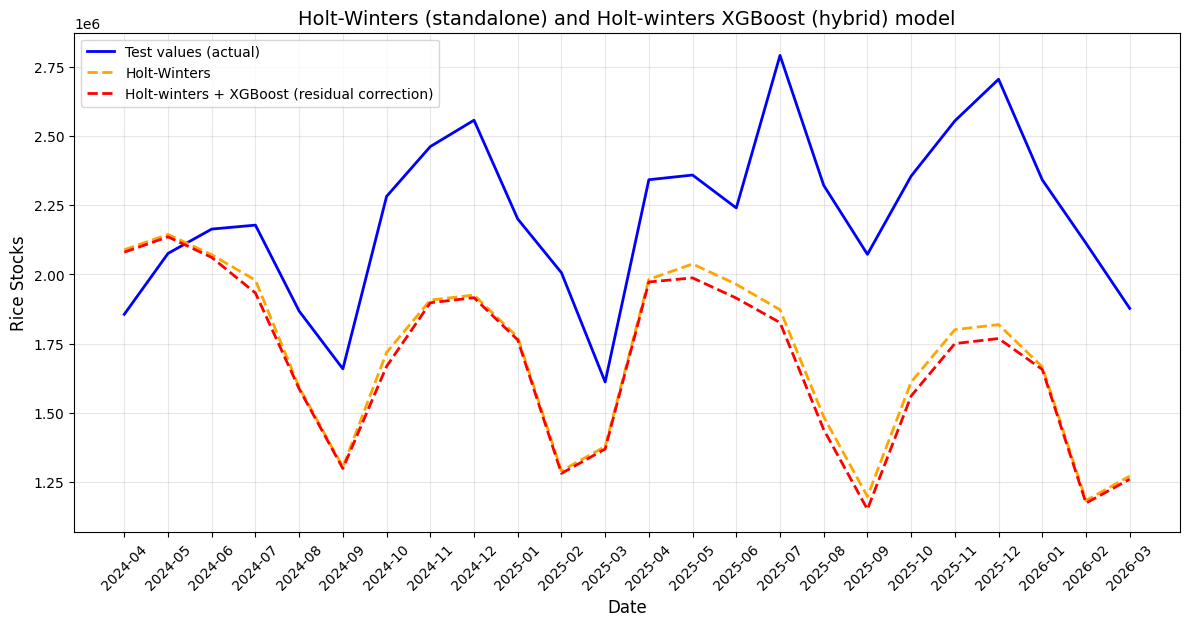

In [60]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Test values (actual)', color='blue', linewidth=2)

# Holt-winters standalone
plt.plot(data['date'].iloc[-holdout_size:], hw_forecast, label=f'Holt-Winters', color='orange', linestyle='--', linewidth=2)

# Predicted Values
plt.plot(data['date'].iloc[-holdout_size:], final_hybrid_forecast, label=f'Holt-winters + XGBoost (residual correction)', color='red', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters (standalone) and Holt-winters XGBoost (hybrid) model', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [61]:
hybrid_mape = mean_absolute_percentage_error(test, final_hybrid_forecast)
hybrid_mae = mean_absolute_error(test, final_hybrid_forecast)
hybrid_rmse = root_mean_squared_error(test, final_hybrid_forecast)
hybrid_r2 = r2_score(test, final_hybrid_forecast)

print(f"Final Hybrid Model MAPE {round(hybrid_mape, 4)}\n"
f"Final Model MAE: {round(hybrid_mae, 4)}\n"
f"Final Model RMSE: {round(hybrid_rmse, 4)}\n"
f"Final Model R2: {round(hybrid_r2, 4)}")

Final Hybrid Model MAPE 0.2428
Final Model MAE: 545664.7929
Final Model RMSE: 613190.1544
Final Model R2: -3.328


### Save gridsearch (hybrid model)

In [ ]:
hybrid_gridsearch = grid_search

In [ ]:
dump(hybrid_gridsearch, 'hybrid_gridsearch.pkl')

['hybrid_gridsearch.pkl']

### XGBoost standalone

In [107]:
testings = xgb.drop(columns=['stock_total']).iloc[-48:-holdout_size]

In [108]:
testings

,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price,rol_stock_total,is_lean_month,date
date,,,,,,,,,,
2022-04,1464978.00,738160.00,241170.9,33.39,37.43,38.22,43.13,2.365824e+06,0,2022-04
2022-05,1425103.00,918668.35,241126.0,33.45,37.41,38.38,43.18,2.372193e+06,0,2022-05
2022-06,1132455.00,1173281.49,225087.0,33.79,37.65,38.29,43.16,2.356016e+06,0,2022-06
2022-07,985551.00,986310.00,205820.0,34.18,37.99,38.41,43.27,2.367256e+06,1,2022-07
2022-08,751071.00,648399.23,178842.0,34.40,38.08,38.44,43.45,2.373333e+06,1,2022-08
2022-09,638163.00,543023.90,151170.0,34.13,37.95,38.45,43.37,2.356004e+06,1,2022-09
2022-10,1059684.00,728694.67,166342.0,33.66,37.46,38.37,43.27,2.318299e+06,0,2022-10
2022-11,1332368.00,841738.07,244323.0,33.83,37.54,38.18,43.25,2.261103e+06,0,2022-11
2022-12,1296967.60,831165.69,249713.0,34.02,37.66,38.13,43.22,2.199427e+06,0,2022-12


In [109]:
xgb = total_stock

X_train = xgb.drop(columns=['stock_total']).iloc[:-holdout_size - 24]
y_train = xgb['stock_total'].iloc[:-holdout_size - 24]
X_val = xgb.drop(columns=['stock_total']).iloc[-48:-holdout_size]
y_val = xgb['stock_total'].iloc[-48:-holdout_size]

# xgb_test = xgb.drop(columns=['stock_total']).iloc[-24:]

In [110]:
X_train['is_lean_month'] = X_train.is_lean_month.astype('int')

In [111]:
X_train = total_stock.drop(columns=['stock_total']).iloc[:-holdout_size]
y_train = total_stock['stock_total'].iloc[:-holdout_size]

if 'date' in X_train.columns:
  X_train = X_train.drop(columns=['date'])

# X_test = total_stock.drop(columns=['stock_total']).iloc[-holdout_size:]
# y_test = total_stock['stock_total'].iloc[-holdout_size:]

# X_train = add_lean_months(X_train)
# X_test = add_lean_months(X_test)

In [112]:
grid_search.fit(X_train, y_train,
    # eval_metric="rmse",
    verbose=False)

# The 'best_model' now contains the XGBoost model trained on the WHOLE dataset
best_xgb_model = grid_search.best_estimator_

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [09:32:00] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [113]:
xgb_test_data['is_lean_month'] = xgb_test_data.is_lean_month.astype('int')
xgb_model_forecast = best_xgb_model.predict(xgb_test_data[-24:])

In [114]:
best_xgb_model

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping=True,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=2, max_leaves=None,
             min_child_weight=5, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=300, n_jobs=None, ...)

### Visualization: XGBoost standalone

In [115]:
xgb_model_forecast

array([2139935. , 2312504.5, 2207152.8, 2171188.2, 1956893. , 1970626.4,
       2471450.2, 2469704.8, 2570387.2, 2667029.8, 2204962.2, 2308439.5,
       2566351.8, 2382272.2, 2305710. , 2231554.5, 1935430.2, 1789225. ,
       2470267. , 2390306. , 2390306. , 2505502.5, 2124515.8, 2069072.4],
      dtype=float32)

In [ ]:
# For log transformed target variables only
xgb_model_tforecast = np.expm1(xgb_model_forecast)
xgb_model_tforecast

/tmp/ipykernel_955/1767149315.py:2: RuntimeWarning: overflow encountered in expm1
  xgb_model_tforecast = np.expm1(xgb_model_forecast)


array([inf, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf,
       inf, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf],
      dtype=float32)

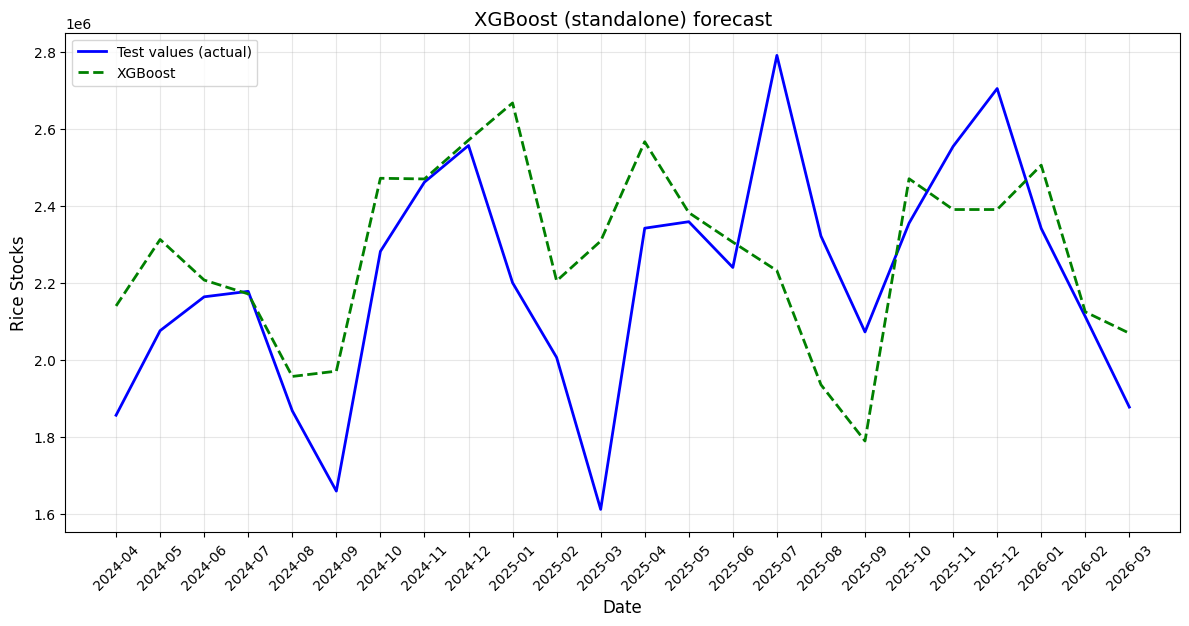

In [116]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Test values (actual)', color='blue', linewidth=2)
'''
# Holt-winters standalone
plt.plot(data['date'].iloc[-holdout_size:], final_forecast, label=f'Holt-Winters', color='red', linestyle='--', linewidth=2)

# Hybrid forecast
plt.plot(data['date'].iloc[-holdout_size:], final_hybrid_forecast, label=f'Holt-winters + XGBoost (residual correction)', color='orange', linestyle='--', linewidth=2)
'''
# XGBoost standalone
plt.plot(data['date'].iloc[-holdout_size:], xgb_model_forecast, label=f'XGBoost', color='green', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost (standalone) forecast', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [117]:
xgb_mape = mean_absolute_percentage_error(test, xgb_model_forecast)
xgb_mae = mean_absolute_error(test, xgb_model_forecast)
xgb_rmse = root_mean_squared_error(test, xgb_model_forecast)
xgb_r2 = r2_score(test, xgb_model_forecast)

print(f"Final Model MAPE {round(xgb_mape, 4)}\n"
f"Final Model MAE: {round(xgb_mae, 4)}\n"
f"Final Model RMSE: {round(xgb_rmse, 4)}\n"
f"Final Model R2: {round(xgb_r2, 4)}")

Final Model MAPE 0.1003
Final Model MAE: 210395.6775
Final Model RMSE: 275560.1107
Final Model R2: 0.126


### Feature importance

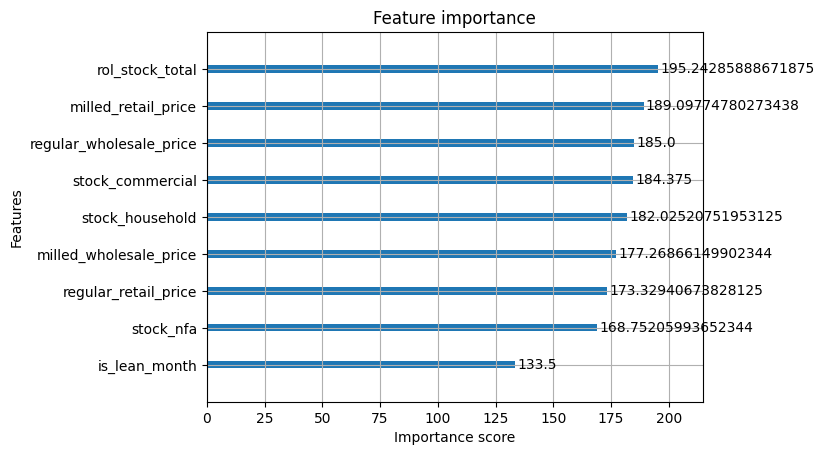

In [118]:
from xgboost import plot_importance
plot_importance(best_xgb_model, importance_type='cover')
plt.show()

### Save model (xgboost standalone)

In [ ]:
xgb_gridsearch = grid_search

In [ ]:
dump(xgb_gridsearch, 'xgb_gridsearch')

['xgb_gridsearch']

### Comparison of models

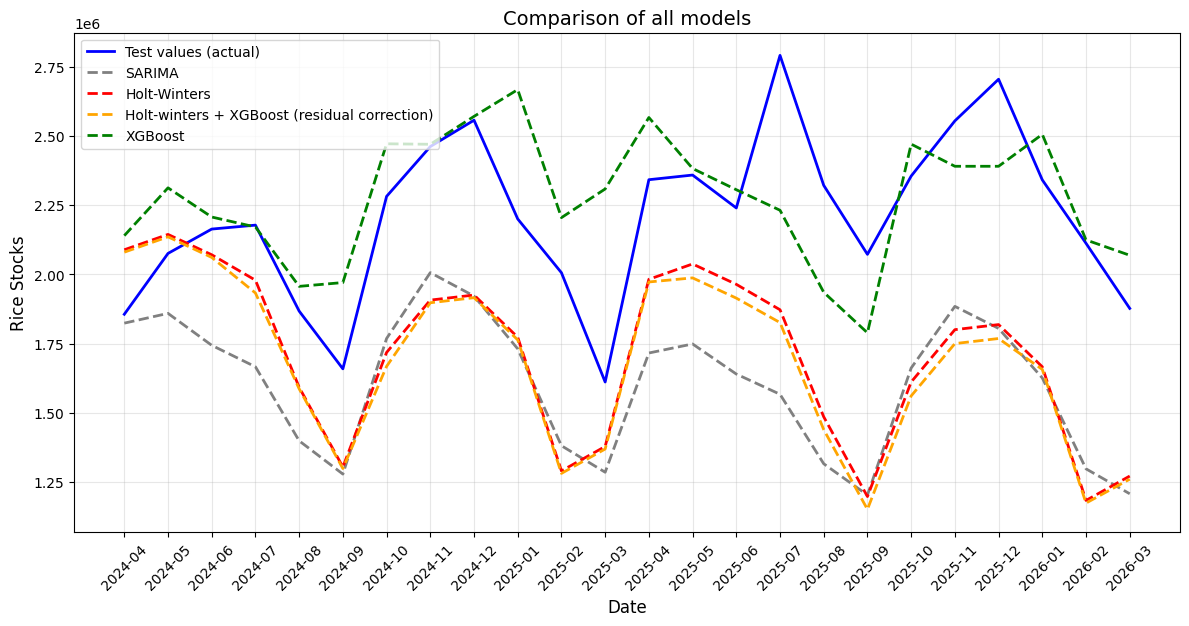

In [119]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Test values (actual)', color='blue', linewidth=2)

# SARIMA
plt.plot(data['date'].iloc[-holdout_size:], sarima_forecast, label=f'SARIMA', color='gray', linestyle='--', linewidth=2)

# Holt-winters standalone
plt.plot(data['date'].iloc[-holdout_size:], hw_forecast, label=f'Holt-Winters', color='red', linestyle='--', linewidth=2)

# Hybrid forecast
plt.plot(data['date'].iloc[-holdout_size:], final_hybrid_forecast, label=f'Holt-winters + XGBoost (residual correction)', color='orange', linestyle='--', linewidth=2)

# XGBoost standalone
plt.plot(data['date'].iloc[-holdout_size:], xgb_model_forecast, label=f'XGBoost', color='green', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Comparison of all models', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [120]:
metrics_dict = {
    "MAPE": [sarima_mape, hw_mape, hybrid_mape, xgb_mape],
    "MAE": [sarima_mae, hw_mae, hybrid_mae, xgb_mae],
    "RMSE": [sarima_rmse, hw_rmse, hybrid_rmse, xgb_rmse],
    "R2": [sarima_r2, hw_r2, hybrid_r2, xgb_r2]
}

models = ['Sarima', 'Holt-winters', 'Holt-Winters and XGBoost', 'XGBoost standalone']

# Display as a DataFrame
metrics_df = pd.DataFrame(metrics_dict, models)
print(metrics_df)

                              MAPE            MAE           RMSE        R2
Sarima                    0.268077  601676.492303  651255.004022 -3.881974
Holt-winters              0.232441  521655.059530  587335.292374 -2.970686
Holt-Winters and XGBoost  0.242771  545664.792888  613190.154363 -3.327964
XGBoost standalone        0.100294  210395.677500  275560.110676  0.125971


### Use remaining 12 features (remaining_features) for forecast

In [121]:
if 'stock_total' in remaining_features.columns:
  remaining_features = remaining_features.drop(columns=['stock_total'])
remaining_features = add_lean_months(remaining_features)

In [122]:
# remaining_features['date'] = remaining_features.index.astype(str)
future_pred = pd.concat([total_stock.iloc[-holdout_size:], remaining_features], axis=0)
future_pred['date'] = future_pred.index.astype(str)

In [123]:
future_pred = add_lean_months(future_pred)

In [124]:
xgb_future_forecast = best_xgb_model.predict(future_pred.drop(columns=['date', 'stock_total']).iloc[-12:])
xgb_future_forecast

array([2613399. , 2594576. , 2555615.5, 2462228.5, 2132479.5, 2185044.2,
       2346182.5, 2484654.5, 2613425. , 2601320.5, 2551265. , 2352324.5],
      dtype=float32)

In [125]:
# xgb_future_tforecast = np.expm1(xgb_future_forecast)
xgb_future_forecast = xgb_future_forecast
xgb_future_forecast

array([2613399. , 2594576. , 2555615.5, 2462228.5, 2132479.5, 2185044.2,
       2346182.5, 2484654.5, 2613425. , 2601320.5, 2551265. , 2352324.5],
      dtype=float32)

### Visualization: XGBoost standalone prediction

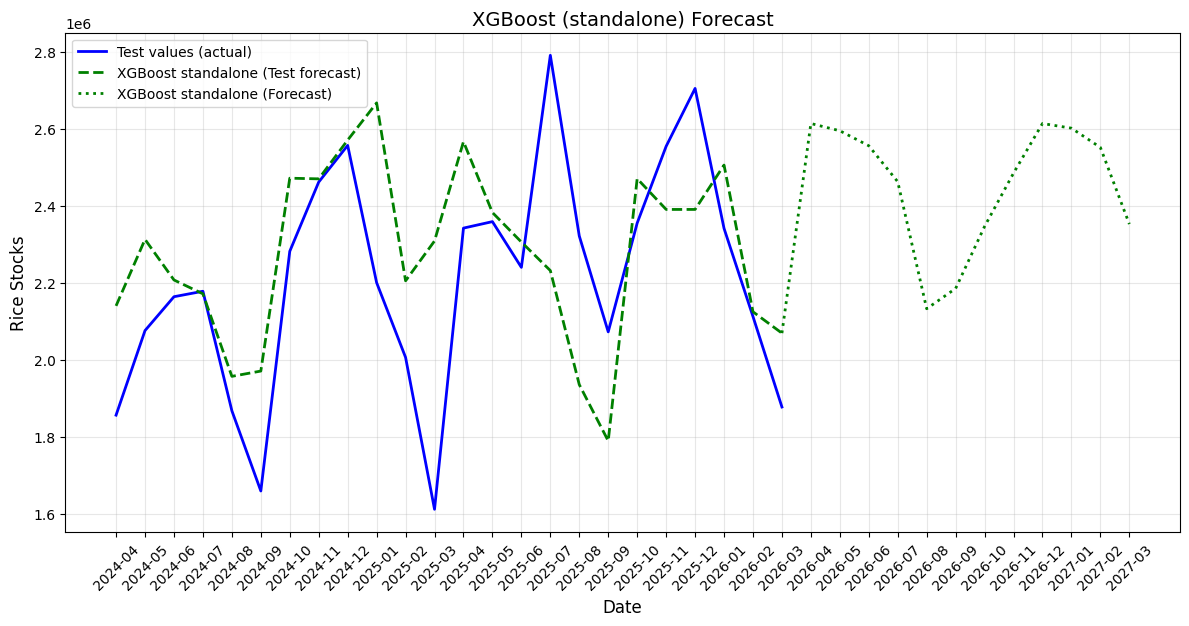

In [126]:
import pandas as pd

start_date = total_stock.index[-holdout_size:].min()
end_date = future_pred.index.max()
date_range_str = f"({start_date} to {end_date})"

# ==========================================================
# 1. BRIDGE THE GAP (Connecting Orange to Green)
# ==========================================================
# Get the exact handoff date (last date of the historical/test set)
handoff_date = data['date'].iloc[-1]

# Extract the last predicted value from the historical XGBoost model (Orange line's end)
last_xgb_pred = xgb_model_forecast.iloc[-1] if hasattr(xgb_model_forecast, 'iloc') else xgb_model_forecast[-1]

# Prepend that handoff point to your future data arrays
future_dates_connected = pd.concat([pd.Series([handoff_date]), future_pred['date'].iloc[-12:]])
future_vals_connected = pd.concat([pd.Series([last_xgb_pred]), pd.Series(xgb_future_forecast).iloc[-12:]])

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label='Test values (actual)', color='blue', linewidth=2)

# Holt-winters standalone
plt.plot(data['date'].iloc[-holdout_size:], xgb_model_forecast, label='XGBoost standalone (Test forecast)', color='green', linestyle='--', linewidth=2)

# ==========================================================
# UPDATED: Green line now starts precisely where the Green line ended
# ==========================================================
plt.plot(future_dates_connected, future_vals_connected, label='XGBoost standalone (Forecast)', color='green', linestyle=':', linewidth=2)

# 3. Aesthetics
plt.title('XGBoost (standalone) Forecast', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(future_pred['date'][::1].iloc[-36:], rotation=45)

plt.show()

## Features to be added


### eval metrics

In [ ]:
metrics_dict = {
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.85, 0.96],
    "F1-Score": [0.84, 0.96]
}

df = pd.DataFrame(metrics_dict)

# Print standard clean table
print(df.to_string(index=False))

# OR Print as a Markdown table for your docs/reports
print("\n--- Markdown Format ---")
print(df.to_markdown(index=False))

### lag values

In [ ]:
df = pd.DataFrame({'sales': [10, 15, 20, 25, 30, 35]})

# Creating lags
df['lag_1'] = df['sales'].shift(1, freq='D')
df['lag_2'] = df['sales'].shift(2)
# df['lag_7'] = df['sales'].shift(7) # Useful for weekly seasonality

print(df)

NotImplementedError: This method is only implemented for DatetimeIndex, PeriodIndex and TimedeltaIndex; Got type RangeIndex

In [ ]:
df = pd.DataFrame(
    [[10, 13, 17], [20, 23, 27], [15, 18, 22], [30, 33, 37], [45, 48, 52]],
    columns=["Col1", "Col2", "Col3"],
    index=pd.date_range("2020-01-01", "2020-01-05"))
df

,Col1,Col2,Col3
2020-01-01,10,13,17
2020-01-02,20,23,27
2020-01-03,15,18,22
2020-01-04,30,33,37
2020-01-05,45,48,52


In [ ]:
df.shift(periods=3, freq="infer")

,Col1,Col2,Col3
2020-01-04,10,13,17
2020-01-05,20,23,27
2020-01-06,15,18,22
2020-01-07,30,33,37
2020-01-08,45,48,52


In [ ]:
test = data_xgb[['date', 'stock_household']]
test.index = pd.to_datetime(test['date']).dt.to_period('M')
test = test.drop(columns=['date'])

# test.shift(periods=3, freq="infer")
# test['stock_household_lag_1'] = test['stock_household'].shift(1, freq='M')
test_new = test['stock_household'].shift(3, freq='M')
test_new = pd.DataFrame(test_new)
test_new.rename(columns={'stock_household' : 'stock_household_lag'}, inplace=True)

new = pd.concat([test, test_new], axis=1)
new


,stock_household,stock_household_lag
date,,
2000-01,1149700.00,NaN
2000-02,1009500.00,NaN
2000-03,832200.00,NaN
2000-04,954400.00,1149700.00
2000-05,1059500.00,1009500.00
...,...,...
2024-02,685199.12,1017221.98
2024-03,694618.06,986776.75
2024-04,NaN,1000502.23


In [ ]:
new_data = data.drop(columns=['stock_total', 'is_lean_month', 'month'])
new_data.index = pd.to_datetime(data['date']).dt.to_period('M')
new_data = new_data.drop(columns=['date'])

new_data = new_data.shift(periods=6, freq="infer")
# new_data = pd.concat([new_data, data['stock_total']], axis=1)
# new_data = pd.concat([data['stock_total'], new_data], axis=1)
stock_total = data[['date', 'stock_total']]
stock_total.index = pd.to_datetime(stock_total['date']).dt.to_period('M')
stock_total = stock_total.drop(columns=['date'])

new_data = pd.concat([stock_total, new_data], axis=1)
new_data

,stock_total,stock_household,stock_commercial,stock_nfa,regular_wholesale_price,milled_wholesale_price,regular_retail_price,milled_retail_price
date,,,,,,,,
2000-01,2364500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-02,2042300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-03,1765700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-04,1874900.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-05,2067000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
2026-05,NaN,1149260.99,944142.43,460735.00,35.65,40.28,40.29,46.80
2026-06,NaN,1026400.66,1221968.35,456138.00,37.83,42.94,41.49,48.25
2026-07,NaN,1043525.46,858877.00,438752.60,39.81,45.16,43.29,50.05


### display all data values

In [ ]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(new_data[-6:])

         stock_total  stock_household  stock_commercial  stock_nfa  \
date                                                                 
2026-04          NaN        952087.39         954908.93  447900.00   
2026-05          NaN       1149260.99         944142.43  460735.00   
2026-06          NaN       1026400.66        1221968.35  456138.00   
2026-07          NaN       1043525.46         858877.00  438752.60   
2026-08          NaN        899568.63         791200.85  421512.67   
2026-09          NaN        908721.92         564220.75  404386.21   

         regular_wholesale_price  milled_wholesale_price  \
date                                                       
2026-04                    34.68                   39.48   
2026-05                    35.65                   40.28   
2026-06                    37.83                   42.94   
2026-07                    39.81                   45.16   
2026-08                    41.60                   47.72   
2026-09            

In [ ]:
def lean(dataset):
  lean = set([7, 8, 9])
  dataset['is_lean_month'] = np.where(dataset.index.month.isin(lean), '1', '0')
  return dataset

### Save the model

In [ ]:
import joblib

# 1. Save the model to a file
model_filename = ""
joblib.dump(final_model, model_filename)
print(f"Model saved successfully as {model_filename}")

# --- Later, in a different script or session ---

# 2. Load the model
loaded_model = joblib.load(model_filename)

# 3. Predict the next 12 months (out-of-sample)
# Note: This doesn't require the training data to be present!
future_forecast = loaded_model.forecast(12)
print("\nFuture 12-Month Forecast:")
print(future_forecast)

### add loss curve

In [ ]:
from sklearn.model_selection import GridSearchCV, train_test_split
# Generate dummy data: 1000 rows, 5 features
np.random.seed(42)
X = np.random.rand(1000, 5)
# Target is a combination of features + noise
y = (X[:, 0] * 2) + (X[:, 1] ** 2) - (X[:, 2] * 1.5) + np.random.normal(0, 0.1, 1000)

# Step 1: Split into Train (70%) and Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 2: Split Temp into Validation (15%) and Test (15%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [ ]:
# Initialize the model
xgb_model = XGBRegressor(n_estimators=100, objective='reg:squarederror')

# Define parameters to test
param_grid = {
    'learning_rate': [0.01, 0.02, 0.05, 0.1, 0.3, 0.5],
    'max_depth': [3, 5, 7, 9, 10]
}

# Setup GridSearchCV
grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=6,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Fit using the validation set for the loss curve
grid.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    # eval_metric="rmse",
    verbose=False
)

GridSearchCV(cv=6,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None...
                                    max_cat_threshold=None,
                                    max_cat_to_onehot=None, max_delta_step=None,
                                    max_depth=None, max_leaves=None,
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=100,
                                    n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.02, 0.05, 0.1, 0.3, 0.5],
                         'max_depth': [3, 5, 7, 9, 10]},
             scoring='neg_mean_squared_error')

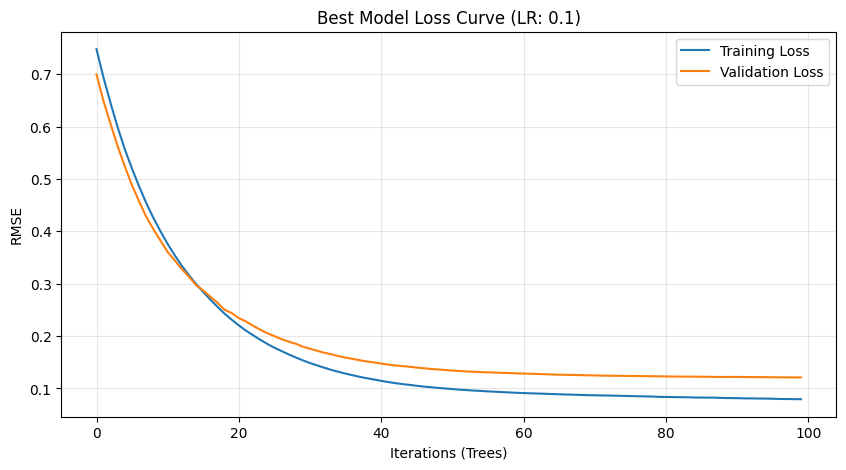

In [ ]:
# Extract evaluation results from the BEST estimator
results = grid.best_estimator_.evals_result()

plt.figure(figsize=(10, 5))
plt.plot(results['validation_0']['rmse'], label='Training Loss')
plt.plot(results['validation_1']['rmse'], label='Validation Loss')
plt.title(f"Best Model Loss Curve (LR: {grid.best_params_['learning_rate']})")
plt.xlabel("Iterations (Trees)")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

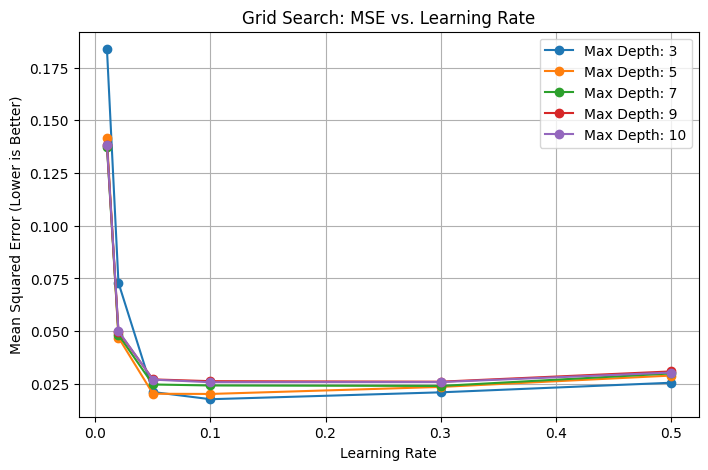

In [ ]:
cv_results = pd.DataFrame(grid.cv_results_)

# Plotting performance vs Learning Rate
plt.figure(figsize=(8, 5))
for depth in param_grid['max_depth']:
    subset = cv_results[cv_results['param_max_depth'] == depth]
    plt.plot(subset['param_learning_rate'], -subset['mean_test_score'], marker='o', label=f'Max Depth: {depth}')

plt.title("Grid Search: MSE vs. Learning Rate")
plt.xlabel("Learning Rate")
plt.ylabel("Mean Squared Error (Lower is Better)")
plt.legend()
plt.grid(True)
plt.show()

### XGBoost (standard) - Loss curve

In [131]:
test_model = grid_search.best_estimator_

In [132]:
t = grid_search.best_estimator_


In [133]:
# X = X_train.reset_index(drop=True)
# y = y_train.reset_index(drop=True)
X = X_train
y = y_train
X_v = X_val
y_v = y_val

In [138]:
if 'date' in X_v.columns:
  X_v = X_v.drop(columns=['date'])

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [08:01:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [08:01:31] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [08:01:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [08:01:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/p

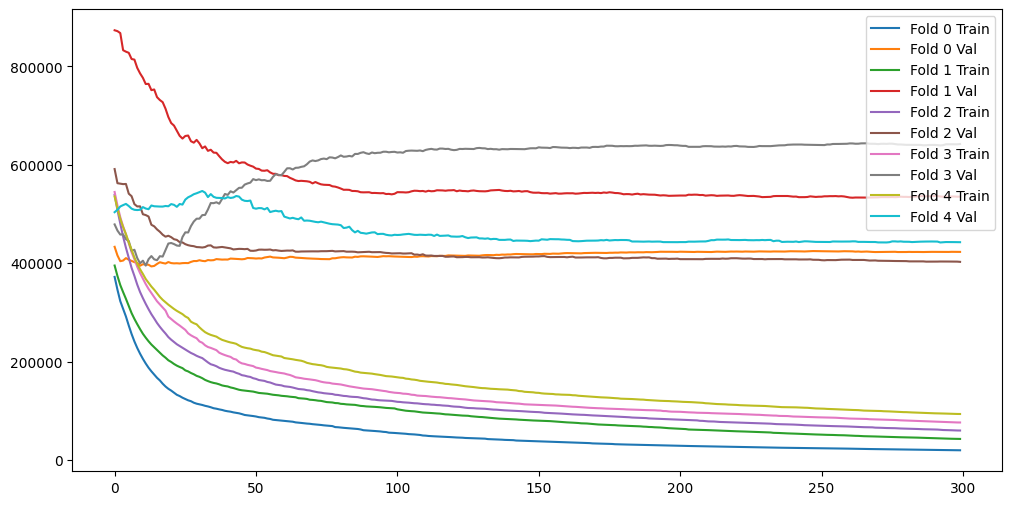

In [84]:
from sklearn.model_selection import TimeSeriesSplit
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_index, val_index) in enumerate(tscv.split(X)):
    X_tr, X_va = X.iloc[train_index], X.iloc[val_index]
    y_tr, y_va = y.iloc[train_index], y.iloc[val_index]

    # Fit your base model manually for this fold
    test_model.fit(
        X_tr, y_tr,
        eval_set=[(X_tr, y_tr), (X_va, y_va)],
        # eval_metric='mape',
        verbose=False
    )

    # Retrieve and plot the loss curve for this specific time-series fold
    results = test_model.evals_result()
    plt.plot(results['validation_0']['rmse'], label=f'Fold {fold} Train')
    plt.plot(results['validation_1']['rmse'], label=f'Fold {fold} Val')

plt.legend()
plt.show()

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [08:01:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


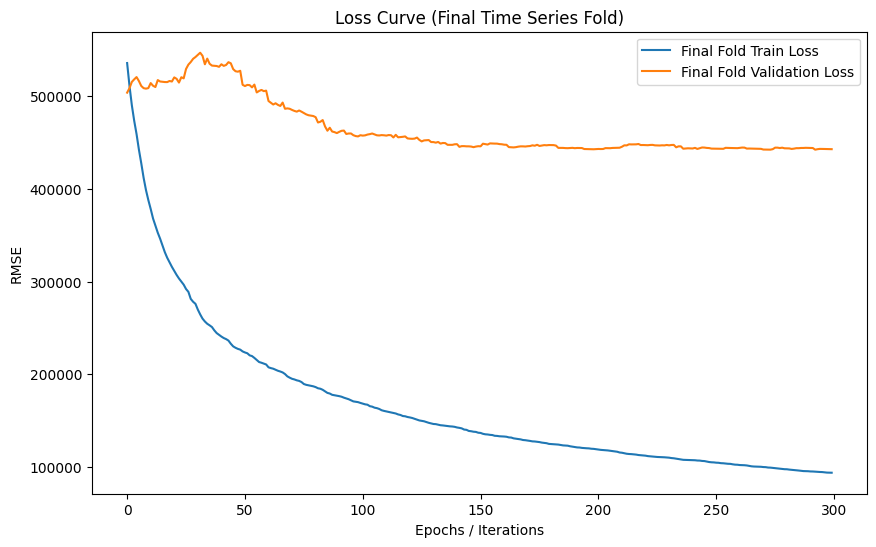

In [85]:
n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)

for fold, (train_index, val_index) in enumerate(tscv.split(X)):
    # We still need to loop to ensure the model trains sequentially through the time series,
    # but we only capture the loss metrics on the very last iteration.
    if fold == n_splits - 1:
        X_tr, X_va = X.iloc[train_index], X.iloc[val_index]
        y_tr, y_va = y.iloc[train_index], y.iloc[val_index]

        # Fit the model on the largest, final historical window
        test_model.fit(
            X_tr, y_tr,
            eval_set=[(X_tr, y_tr), (X_va, y_va)],
            # eval_metric='rmse',
            verbose=False
        )

        # Retrieve and plot the loss curve ONLY for this final fold
        results = test_model.evals_result()

        plt.figure(figsize=(10, 6))
        plt.plot(results['validation_0']['rmse'], label='Final Fold Train Loss')
        plt.plot(results['validation_1']['rmse'], label='Final Fold Validation Loss')
        plt.title('Loss Curve (Final Time Series Fold)')
        plt.xlabel('Epochs / Iterations')
        plt.ylabel('RMSE')
        plt.legend()
        plt.show()

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [09:40:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "early_stopping", "subsample:" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


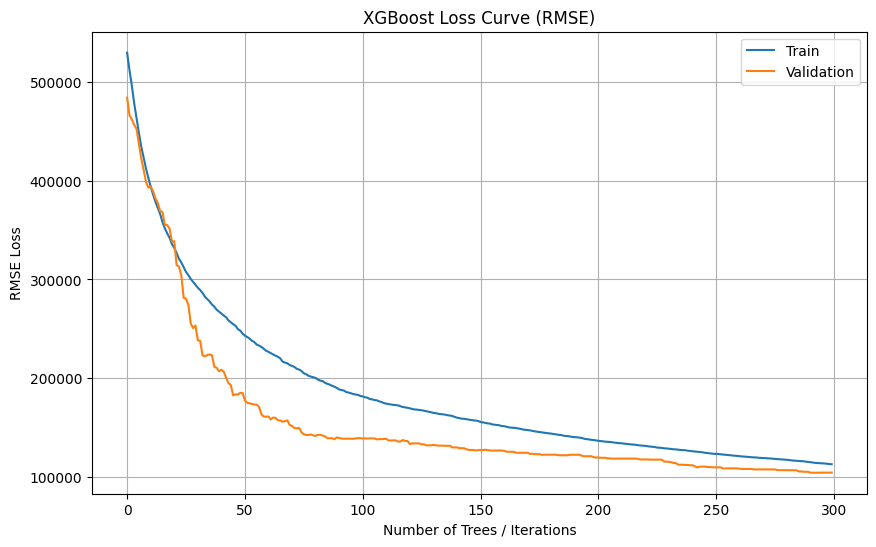

In [141]:
# 2. Train the model (Make sure to pass the eval_set)
test_model.fit(
    X, y,
    eval_set=[(X, y), (X_v, y_v)],
    verbose=False  # Turn off text logs since we are plotting instead
)

# 3. Retrieve evaluation results
results = test_model.evals_result()

# The results dictionary is structured like this:
# {'validation_0': {'rmse': [...]}, 'validation_1': {'rmse': [...]}}
# validation_0 corresponds to the first item in your eval_set (Train)
# validation_1 corresponds to the second item (Val)

epochs = len(results['validation_0']['rmse'])
x_axis = range(0, epochs)

# 4. Plot the loss curves
plt.figure(figsize=(10, 6))
plt.plot(x_axis, results['validation_0']['rmse'], label='Train')
plt.plot(x_axis, results['validation_1']['rmse'], label='Validation')

plt.title('XGBoost Loss Curve (RMSE)')
plt.xlabel('Number of Trees / Iterations')
plt.ylabel('RMSE Loss')
plt.legend()
plt.grid(True)
plt.show()

### Quantile loss (loss function)

In [ ]:
import numpy as np
import xgboost as xgb
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

# 1. Generate synthetic data with some variance
X, y = make_regression(n_samples=1200, n_features=8, noise=10.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Common shared hyperparameters for stability
base_params = {
    'objective': 'reg:quantileerror',
    'n_estimators': 200,
    'learning_rate': 0.05,
    'max_depth': 5,
    'eval_metric': 'quantile',  # Tracks pinball loss on evaluation sets
    'random_state': 42
}

# 2. Train a lower-bound forecaster (10th percentile)
model_low = xgb.XGBRegressor(**base_params, quantile_alpha=0.10)
model_low.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# 3. Train a central forecaster (50th percentile / Median)
model_med = xgb.XGBRegressor(**base_params, quantile_alpha=0.50)
model_med.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# 4. Train an upper-bound forecaster (90th percentile)
model_high = xgb.XGBRegressor(**base_params, quantile_alpha=0.90)
model_high.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# 5. Generate predictions across the distribution
pred_10th = model_low.predict(X_test)
pred_50th = model_med.predict(X_test)
pred_90th = model_high.predict(X_test)

{'validation_0': OrderedDict({'mae': [428524.114806867, 414321.29506437766, 400748.9592274678, 381704.01931330474, 371536.4152360515, 354923.94527896994, 348616.453862661, 337700.7896995708, 325569.089055794, 315023.0166309013, 311274.9463519313, 301317.732832618, 298539.8760729614, 289772.546137339, 287092.17972103006, 280388.4458154506, 274712.41309012874, 270473.27682403434, 265064.7612660944, 259775.4586909871, 255898.955472103, 252285.28326180257, 248120.30579399143, 244168.258583691, 240931.6491416309, 238908.9200643777, 236326.5203862661, 233214.65236051503, 231974.5895922747, 231389.6126609442, 229612.83690987126, 227711.4678111588, 227192.74034334763, 225603.40826180257, 224837.43830472103, 223402.45386266094, 221531.32564377683, 221095.53004291846, 220280.9683476395, 218746.63519313306, 217769.01770386266, 215219.90987124463, 214370.93347639486, 212255.78433476394, 211372.24517167383, 209509.69098712446, 208850.38519313306, 208182.6448497854, 207793.68347639486, 207068.149678

### XGBoost bagging

In [ ]:
from xgboost import XGBRegressor
from sklearn.ensemble import BaggingRegressor

In [ ]:
# Feature engineering across the whole dataset to ensure clean lag alignment


# Separate back into train and test features
X_train = total_stock.drop(columns=['stock_total']).iloc[:-holdout_size]
y_train = total_stock['stock_total'].iloc[:-holdout_size]

X_test = total_stock.drop(columns=['stock_total']).iloc[-holdout_size:]


# 4. MODEL B: BAGGED XGBOOST FORECAST
base_xgb = XGBRegressor(n_estimators=50, max_depth=4, learning_rate=0.5, random_state=42)

bagged_xgb = BaggingRegressor(
    estimator=base_xgb,
    n_estimators=200,
    max_samples=0.8,
    random_state=42,
    oob_score = True
)

# Train the bagged ensemble on the actual target values (not residuals)
bagged_xgb.fit(X_train, y_train)

# Generate XGBoost test predictions
xgb_forecast = bagged_xgb.predict(X_test)
xgb_forecast = pd.Series(xgb_forecast, index=test.index)


# 5. BLEND THE FORECASTS (Weighted Average)
# Let's give Holt-Winters a 60% weight for its strong structural stability,
# and Bagged XGBoost a 40% weight for its agility with recent patterns.
hw_weight = 0.2
xgb_weight = 0.8

hybrid_forecast = (hw_forecast * hw_weight) + (xgb_forecast * xgb_weight)


# 6. DISPLAY RESULTS
output = pd.DataFrame({
    "Actual": test,
    "HW Forecast (60%)": hw_forecast,
    "XGB Forecast (40%)": xgb_forecast,
    "Final Blended Forecast": hybrid_forecast
})
print(output.head())

             Actual  HW Forecast (60%)  XGB Forecast (40%)  \
2024-04  1856160.79       1.853619e+06         2223910.000   
2024-05  2075770.81       1.957073e+06         2293170.500   
2024-06  2163673.78       1.929845e+06         2219899.000   
2024-07  2177878.72       1.730561e+06         2139873.750   
2024-08  1867641.11       1.223998e+06         1987723.875   

         Final Blended Forecast  
2024-04            2.149852e+06  
2024-05            2.225951e+06  
2024-06            2.161888e+06  
2024-07            2.058011e+06  
2024-08            1.834979e+06  


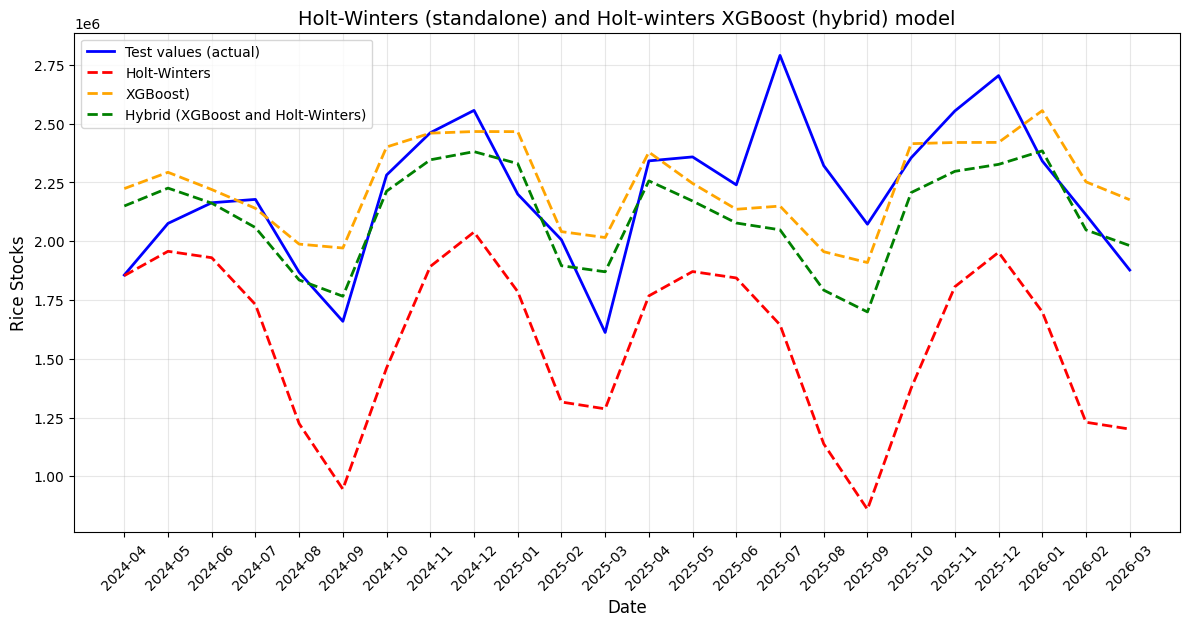

In [ ]:
# 1. Formatting the date range for the legend
start_date = data['date'].iloc[-holdout_size:].min()
end_date = data['date'].iloc[-holdout_size:].max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Actual Values
plt.plot(data['date'].iloc[-holdout_size:], test, label=f'Test values (actual)', color='blue', linewidth=2)

# Holt-winters forecast
plt.plot(data['date'].iloc[-holdout_size:], hw_forecast, label=f'Holt-Winters', color='red', linestyle='--', linewidth=2)

# XGBoost forecast
plt.plot(data['date'].iloc[-holdout_size:], xgb_forecast, label=f'XGBoost)', color='orange', linestyle='--', linewidth=2)

# Hybrid forecast
plt.plot(data['date'].iloc[-holdout_size:], hybrid_forecast, label=f'Hybrid (XGBoost and Holt-Winters)', color='green', linestyle='--', linewidth=2)

# 3. Aesthetics
plt.title('Holt-Winters (standalone) and Holt-winters XGBoost (hybrid) model', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice Stocks', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(data['date'][::1].iloc[-holdout_size:], rotation=45)

plt.show()

In [ ]:
hw_mape, hw_mae, hw_rmse, hw_r2 = mean_absolute_percentage_error(test, hw_forecast), mean_absolute_error(test, hw_forecast), root_mean_squared_error(test, hw_forecast), r2_score(test, hw_forecast)

xgb_mape, xgb_mae, xgb_rmse, xgb_r2 = mean_absolute_percentage_error(test, xgb_forecast), mean_absolute_error(test, xgb_forecast), root_mean_squared_error(test, xgb_forecast),  r2_score(test, xgb_forecast)

hybrid_mape, hybrid_mae, hybrid_rmse, hybrid_r2 = mean_absolute_percentage_error(test, hybrid_forecast), mean_absolute_error(test, hybrid_forecast), root_mean_squared_error(test, hybrid_forecast),  r2_score(test, hybrid_forecast)

metrics_dict = {
    "MAPE": [hw_mape, hybrid_mape, xgb_mape],
    "MAE": [hw_mae, hybrid_mae, xgb_mae],
    "RMSE": [hw_rmse, hybrid_rmse, xgb_rmse],
    "R2": [hw_r2, hybrid_r2, xgb_r2]
}

models = ['Holt-winters', 'Holt-Winters and XGBoost', 'XGBoost bagging']

# Display as a DataFrame
metrics_df = pd.DataFrame(metrics_dict, models)
print(metrics_df)

                              MAPE            MAE           RMSE        R2
Holt-winters              0.285338  632412.683221  702828.406226 -4.685804
Holt-Winters and XGBoost  0.085744  193191.120255  255488.858682  0.248659
XGBoost bagging           0.089670  190958.300833  242393.572785  0.323706


In [ ]:
print(f"OOB Score: {bagged_xgb.oob_score_}")

OOB Score: 0.7518294011458075


In [ ]:
bagged_xgb.oob_prediction_

array([2181356.10027473, 2131159.05405405, 1925203.21428571,
       2140183.9375    , 2183534.76041667, 1902992.88342697,
       1705132.84876543, 1492777.41613924, 1530292.08292079,
       1815117.15081522, 2161186.24739583, 2468686.83909574,
       2304952.72207447, 2016295.3375    , 1941132.07880435,
       2199383.71388889, 2123862.2435567 , 1981123.51157407,
       1986472.70026882, 2007329.90735294, 1555022.30082418,
       1835237.05972222, 2538881.97368421, 2510579.69892473,
       2224999.80965909, 2015858.17977528, 1890266.93465909,
       2204787.23840206, 2205297.16888298, 1867207.08142202,
       1727786.48125   , 1437298.39030612, 1443299.65346535,
       1656057.22979798, 2508757.00921053, 2655345.27873563,
       2265133.35542169, 2143486.35273973, 1961078.65589888,
       2100037.39650538, 2107186.69852941, 1692855.88575269,
       1527134.18382353, 1348497.98271277, 1389694.54123711,
       1758071.4140625 , 2434778.14972527, 2447144.58823529,
       2264132.70833333,

### XGBoost bagging - Loss curve

In [ ]:
test_model = bagged_xgb

In [ ]:
X = X_train
y = y_train

In [ ]:
plt.figure(figsize=(12, 6))
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_index, val_index) in enumerate(tscv.split(X)):
    X_tr, X_va = X.iloc[train_index], X.iloc[val_index]
    y_tr, y_va = y.iloc[train_index], y.iloc[val_index]

    # Fit your base model manually for this fold
    test_model.fit(
        X_tr, y_tr,
        eval_set=[(X_tr, y_tr), (X_va, y_va)],
        # eval_metric='mape',
        verbose=False
    )

    # Retrieve and plot the loss curve for this specific time-series fold
    results = test_model.evals_result()
    plt.plot(results['validation_0']['rmse'], label=f'Fold {fold} Train')
    plt.plot(results['validation_1']['rmse'], label=f'Fold {fold} Val')

plt.legend()
plt.show()

ValueError: Passing extra keyword arguments to BaggingRegressor.fit is only supported if enable_metadata_routing=True, which you can set using `sklearn.set_config`. See the User Guide <https://scikit-learn.org/stable/metadata_routing.html> for more details. Extra parameters passed are: {'verbose', 'eval_set'}

<Figure size 1200x600 with 0 Axes>